# Plot simu vs. obs well data

In [1]:
import geopandas as gpd
from shapely.geometry import Point

In [2]:
%matplotlib inline
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 150

In [3]:
# %matplotlib notebook
# import glob, datetime, ipdb, pickle, pyproj, json, mplleaflet, geopandas, fiona, sys, cartopy, \
#          math, folium, base64
import glob, pickle, os
import numpy as np
import h5py as h5
import math
import pyproj

import matplotlib 
# matplotlib.use('Agg')
import matplotlib.pyplot as plt
# plt.style.use('seaborn-notebook')
import matplotlib.gridspec as gridspec
import matplotlib.dates as mdates

import pandas as pd
# import modin.pandas as pd
import ipywidgets as ipyw
# import cartopy.crs as ccrs
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
# import datetime
from datetime import timedelta, datetime
from scipy import interpolate
# from ipyleaflet import *
# from geojson import Feature, FeatureCollection, Point
from geopandas import GeoDataFrame
# from shapely.geometry import Point
from natsort import natsorted, ns, natsort_keygen
from sklearn.metrics import  mean_squared_error
# from folium.plugins import FloatImage
# from folium import IFrame

import re, lzma

# from tqdm import tqdm_notebook
from tqdm.notebook import tqdm

from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()

from myfunc import insertNA, printname, batch_delta_to_time, get_rmse
from modvis import utils

from fav_colors import fav_colors

from collections import Counter
import seaborn as sns

In [3]:
# from distributed import Client
# client = Client()

## I/O files and parameters (Pin code)

In [4]:
#=======================input==========================
# case_name = "AT-ugrid/TH-hete-bc/"

work_dir = "/pscratch/sd/p/pshuai/HFR-riverbed"
src_dir = "/global/cfs/cdirs/m1800/pin/HFR-riverbed"
case_name = "TH_perm_only_alluvium_2017-2019/"
# case_name = "perm_only_alluvium"
# model_dir = "../model_run/" + case_name
model_dir = os.path.join(work_dir, case_name)
# input_dir = "../model_run/inputs/"
input_dir = os.path.join(src_dir, "model_run", "inputs")
# big_data_dir = "../big_data/"
big_data_dir = "/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/"
# data_dir = "../data/"
data_dir = "/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/"
pickle_dir = os.path.join(src_dir, "output")
# figure_dir = "../figures/"
# fig_dir = "/global/project/projectdirs/pflotran/pin/AT-model/outputs/AT-20x10m/BTC/"
# out_dir = "../results/" + case_name
out_dir = os.path.join(src_dir, "output")
figure_dir = os.path.join(src_dir, "figures")

# # fname_model_origin = model_dir + "model_origin.txt"
# fname_material_h5 = model_dir + "AT_material_river.h5"

# fname_pflotran_h5 = model_dir + "AT-model-noAlluvium.h5"

# fname_300A_h5 = "/Users/shua784/Paraview/300A/John_case_optim_5/pflotran_bigplume-004.h5"

fname_tec_files = model_dir + "/" + "*.pft"
# fname_tec_files = model_dir + "AT-model-spinup-obs-*.tec"
fname_selected_wells = os.path.join( input_dir , "selected_well.txt")

# data_dir = "/global/project/projectdirs/m1800/pin/AT-model/data/"
fname_300A_well_data = big_data_dir + "observations/300A_wells_2008-2019.csv"
fname_WellScreen = data_dir + "well_obs/HEIS_300A_AT_well_screen.csv"
fname_test_well_data = os.path.join(big_data_dir, 'observations/temp_data_all_May-Nov_2019.csv')

# fname_optio2_data = data_dir + "chemistry/Processed_optio2_data_last10m_%O2.csv"
## riverbed temp
# HFR_data_dir = "/global/project/projectdirs/m1800/pin/HFR-thermal/data/"
fname_RG3_T = data_dir + "riverbed_temp/RG3_T3/300_Area_RG3_T3_Temps_20180502.csv"
fname_RG3_T_dat = data_dir + "riverbed_temp/RG3_T3/RG3_T3_Temps.dat"
fname_DA_T = data_dir + "riverbed_temp/DenseArray/DA1_CRiver_TM_T.csv"
fname_100H_dir = data_dir + "riverbed_temp/100H_thermistor_rods/"
iButton_dir = data_dir + 'riverbed_temp/iButton/'

fname_river_stage = big_data_dir + 'boundary_conditions/river_bc/stage_2007-2019/DatumH_River_321.txt'
fname_river_temp = big_data_dir + 'boundary_conditions/river_bc/temp_2007-2019/Temp_River_321.txt'


fname_simu_obs_head = out_dir + "simu_obs_head/"
fname_tracer_spc = out_dir + "tracer_spc/"
fname_head_tracer_spc = out_dir + "head_tracer_spc/"
fname_head_tracer_spc_temp = out_dir + "head_tracer_spc_temp/"
fname_simu_obs_temp = figure_dir + "simu_obs_temp/"

fname_simu_obs_chem = out_dir + "simu_obs_chem/"

# results_dir = "/global/project/projectdirs/m1800/pin/HFR-thorne/results/" + case_name

# fname_river_stage_plot = "/global/project/projectdirs/m1800/pin/AT-model/outputs/AT-ugrid/river_stage/"
# fname_river_temp_stage_plot = "/global/project/projectdirs/m1800/pin/AT-model/outputs/AT-ugrid/river_temp_stage/"

# input_dir = "/global/project/projectdirs/m1800/pin/HFR-thorne/inputs/"

In [5]:
# date_origin = datetime.strptime("2007-01-01 00:00:00", "%Y-%m-%d %H:%M:%S")
date_origin = datetime.strptime("2017-01-01 00:00:00", "%Y-%m-%d %H:%M:%S")
# model_origin = [594462.6688, 116280.5661] 

In [6]:
P_atm = 101325
rho = 997.16
g_const = 9.81

## import well data

In [23]:
# obs_data_df = pd.read_csv(fname_well_data, parse_dates=["DateTime"])
# fname_300A_well_data = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/observations/300A_wells_2008-2019.csv'
obs_data_df = pd.read_csv(fname_300A_well_data)
# obs_data_df['DateTime'] = pd.to_datetime(obs_data_df['DateTime'],format='%m/%d/%y %H:%M:%S')
obs_data_df['DateTime'] = pd.to_datetime(obs_data_df['DateTime'],format='%Y-%m-%d %H:%M:%S')

In [24]:
print(obs_data_df.keys())
print(obs_data_df['WellName'])
print(obs_data_df['DateTime'])
print(obs_data_df.head)

Index(['DateTime', 'Temp', 'SpC', 'WL', 'WellName'], dtype='object')
0          399-1-1
1          399-1-1
2          399-1-1
3          399-1-1
4          399-1-1
            ...   
3357139      SWS-1
3357140      SWS-1
3357141      SWS-1
3357142      SWS-1
3357143      SWS-1
Name: WellName, Length: 3357144, dtype: object
0         2008-01-01 00:00:00
1         2008-01-01 01:00:00
2         2008-01-01 02:00:00
3         2008-01-01 03:00:00
4         2008-01-01 04:00:00
                  ...        
3357139   2019-12-31 19:00:00
3357140   2019-12-31 20:00:00
3357141   2019-12-31 21:00:00
3357142   2019-12-31 22:00:00
3357143   2019-12-31 23:00:00
Name: DateTime, Length: 3357144, dtype: datetime64[ns]
<bound method NDFrame.head of                    DateTime      Temp     SpC        WL WellName
0       2008-01-01 00:00:00  18.37000  0.3630  105.1907  399-1-1
1       2008-01-01 01:00:00  18.38000  0.3630  105.1835  399-1-1
2       2008-01-01 02:00:00  18.39000  0.3620  105.1763  399-1-1


In [9]:
obs_well_list = obs_data_df['WellName'].unique()
obs_well_list = ['Well_' + i for i in obs_well_list]

In [10]:
print(len(obs_data_df['DateTime'].unique()))

105183


In [11]:
print('total number of well data: {0}'.format(len(obs_well_list)))
obs_well_list

total number of well data: 50


['Well_399-1-1',
 'Well_399-1-10A',
 'Well_399-1-11',
 'Well_399-1-12',
 'Well_399-1-16A',
 'Well_399-1-17A',
 'Well_399-1-32',
 'Well_399-2-1',
 'Well_399-2-2',
 'Well_399-2-3',
 'Well_399-2-5',
 'Well_399-3-18',
 'Well_399-3-19',
 'Well_399-3-20',
 'Well_399-3-21',
 'Well_399-3-22',
 'Well_399-4-9',
 'Well_399-1-2',
 'Well_399-1-7',
 'Well_399-1-21A',
 'Well_399-1-23',
 'Well_399-2-10',
 'Well_399-3-26',
 'Well_399-5-1',
 'Well_399-6-1',
 'Well_399-8-1',
 'Well_399-1-15',
 'Well_399-1-60',
 'Well_399-2-33',
 'Well_399-3-29',
 'Well_399-3-34',
 'Well_399-3-37',
 'Well_399-4-7',
 'Well_399-8-5A',
 'Well_699-S19-E13',
 'Well_699-S19-E14',
 'Well_699-S27-E12A',
 'Well_699-S27-E14',
 'Well_699-S29-E13A',
 'Well_399-1-21B',
 'Well_399-1-57',
 'Well_399-2-25',
 'Well_399-2-32',
 'Well_SWS-1',
 'Well_399-3-9',
 'Well_399-3-10',
 'Well_NRG',
 'Well_699-S11-E12A',
 'Well_399-4-11',
 'Well_399-4-15']

In [12]:
# obs_data_df = pd.read_csv(fname_well_data, parse_dates=["DateTime"])
# fname_test_well_data = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/observations/temp_data_all_May-Nov_2019.csv'
obs_df = pd.read_csv(fname_test_well_data)
# obs_data_df['DateTime'] = pd.to_datetime(obs_data_df['DateTime'],format='%m/%d/%y %H:%M:%S')
obs_df['DateTime'] = pd.to_datetime(obs_df['DateTime'],format='%Y-%m-%d %H:%M:%S')

### import river stage & temp

In [13]:
# downstream location MASS1-321
# fname_river_stage = '/global/homes/z/zc727/HFR/data/stage_2007-2019/DatumH_River_321.txt' # '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/boundary_conditions/river_bc/stage_2007-2019/DatumH_River_321.txt'
river_stage = pd.read_csv(fname_river_stage, header = None, sep = " ", 
                          names= ['dt', 'Easting', 'Northing', 'wl'])
river_stage['datetime'] = [date_origin + timedelta(seconds = i) for i in river_stage['dt'].values]
river_stage.set_index('datetime', drop = False, inplace = True)

In [14]:
# fname_river_temp ='/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/boundary_conditions/river_bc/temp_2007-2019/Temp_River_321.txt'
river_temp = pd.read_csv(fname_river_temp, header = None, sep = " ", 
                          names= ['dt', 'temp'])
river_temp['datetime'] = [date_origin + timedelta(seconds = i) for i in river_temp['dt'].values]
river_temp.set_index('datetime', drop = False, inplace = True)

### import well screen

In [15]:
# fname_WellScreen = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/well_obs/HEIS_300A_AT_well_screen.csv'
well_screen = pd.read_csv(fname_WellScreen)

In [16]:
print(well_screen.keys())
print(well_screen.index)

Index(['Well_ID', 'WellName', 'Easting', 'Northing', 'CASING_ELEVATION',
       'SCREEN_ELEV_TOP', 'SCREEN_ELEV_BOTTOM'],
      dtype='object')
RangeIndex(start=0, stop=1024, step=1)


## export simulated head using observation files

We will import well observation from .tec outputs.

In [27]:
#pickle_dir = '/global/homes/z/zc727/HFR/output/'   #'/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/pickle/'
#case_name = "TH-heatBC-mesh_100m-rst1/"
#with lzma.open(pickle_dir + f"{case_name[:-1]}-well_data_df_ave.xz", 'rb') as f:
#    well_data_df = pd.read_pickle(f) #pickle.load(f)       

In [25]:
#print(well_data_df.keys())
#print(well_data_df.index)

MultiIndex([(    'RG3_T3_24cm',   'Liquid Pressure [Pa]',     'RG3_T3_24cm'),
            (    'RG3_T3_24cm',        'Temperature [C]',     'RG3_T3_24cm'),
            (    'RG3_T3_24cm', 'Total Tracer_river [M]',     'RG3_T3_24cm'),
            (    'RG3_T3_24cm',              'qlx [m/h]',     'RG3_T3_24cm'),
            (    'RG3_T3_24cm',              'qly [m/h]',     'RG3_T3_24cm'),
            (    'RG3_T3_64cm',   'Liquid Pressure [Pa]',     'RG3_T3_64cm'),
            (    'RG3_T3_64cm',        'Temperature [C]',     'RG3_T3_64cm'),
            (    'RG3_T3_64cm', 'Total Tracer_river [M]',     'RG3_T3_64cm'),
            (    'RG3_T3_64cm',              'qlx [m/h]',     'RG3_T3_64cm'),
            (    'RG3_T3_64cm',              'qly [m/h]',     'RG3_T3_64cm'),
            ...
            (  'Well_699-8-32', 'Total Tracer_river [M]', 'flux_ave_tracer'),
            (  'Well_699-8-32',        'Temperature [C]',   'flux_ave_temp'),
            ('iButton_B2_28cm', 'Total Tracer_ri

In [14]:
# simu_time = np.array([date_origin + timedelta(hours=i) for i in well_data_df.index])

In [ ]:
# with open(results_dir + "well_data_df.p", 'rb') as f:
#     well_data_df = pickle.load(f)

# with open(results_dir + "obs_pts_df.p", 'rb') as f:
#     obs_pts_df = pickle.load(f)

# with open(results_dir + "selected_obs_wells.p", 'rb') as f:
#     selected_obs_wells = pickle.load(f)

In [17]:
# fname_selected_wells = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/model_run/inputs/selected_well.txt'
simu_well_list = pd.read_csv(fname_selected_wells,  header=None, names=['WellName'])
simu_well_list = simu_well_list['WellName'].values.tolist()

In [18]:
print('total number of simulation well: {0}'.format(len(simu_well_list)))
print('(unique)total number of simulation well: {0}'.format(len(np.unique(simu_well_list))))

total number of simulation well: 920
(unique)total number of simulation well: 920


In [ ]:
# simu_time = np.array([date_origin + timedelta(hours=i) for i in well_data_df.index])

### assemble all output data file

In [19]:
# with open(results_dir + "well_data_df-300A.p", 'rb') as f:
#     simu_time, well_data_df = pickle.load(f)

# with open(results_dir + "obs_pts_df.p", 'rb') as f:
#     obs_pts_df = pickle.load(f)

# with lzma.open(pickle_dir + f'{case_name[:-1]}-simu_data_df.xz', "rb") as f:
#    simu_data_df = pd.read_pickle(f)
    
with lzma.open(os.path.join(pickle_dir , f"{case_name[:-1]}-well_data_df_ave.xz"), 'rb') as f:
    well_data_df = pd.read_pickle(f)

In [25]:
#fname_tec_files = '/pscratch/sd/z/zc727/model_iso_perm/'+'*.pft'       # isotropic permeability
#fname_tec_files = '/pscratch/sd/z/zc727/model_aniso_perm_except_basalt/'+'*.pft'      # anisotropic permeability, except basalt
# fname_tec_files = '/pscratch/sd/z/zc727/model_aniso_perm_only_alluvium/'+'*.pft'       # anisotropic permeability, only alluvium
tec_files = glob.glob(fname_tec_files)
tec_files = natsorted(tec_files)
assert(len(tec_files) > 0),"No such files found in the specified directory."
# Optional: Print the sorted file list for verification
for file in tec_files:
    print(file)

/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-12.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-45.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-86.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-128.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-146.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-156.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-187.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-228.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-266.pft
/psc

This may take a while...

In [26]:
simu_data_df = pd.DataFrame()

for ifile in tqdm(tec_files[:]):   
# ifile = '/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium/TH_perm_only_alluvium-obs-96.pft'
    print(ifile)
    idf_header_row = pd.read_table(ifile, sep=',',header=None, nrows=1, engine='python')
    iheader = list(np.asarray(idf_header_row.values).flatten())
    idf = pd.read_table(ifile, sep='\s+',header=None, names=iheader, index_col=0, skiprows=1, engine='python')
    
    simu_data_df = pd.concat([simu_data_df, idf], axis=1, join='outer')

  0%|          | 0/57 [00:00<?, ?it/s]

/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-12.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-45.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-86.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-128.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-146.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-156.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-187.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-228.pft
/pscratch/sd/p/pshuai/HFR-riverbed/TH_perm_only_alluvium_2017-2019/TH_perm_only_alluvium_2017-2019-obs-266.pft
/psc

In [51]:
# #interpret code by Chao
# sum = []
# for ifile in tqdm(tec_files[:]):   
# #     ifile = '/global/cscratch1/sd/pshuai/TH-100x100x2-thermal/TH_100x100x2_thermal-obs-1238.tec'
# #     print(ifile)
#     idf_header_row = pd.read_table(ifile, sep=',',header=None, nrows=1, engine='python')
#     iheader = list(np.asarray(idf_header_row.values).flatten())
#     idf = pd.read_table(ifile, sep='\s+',header=None, names=iheader, index_col=0, skiprows=1, engine='python')
#     print('file name: {0}, data number: {1}'.format(ifile,len(idf.columns)/6))
#     sum.append(len(idf.columns)/6)
# print('total data number: {0}'.format(np.sum(sum)))

In [57]:
# pickle_dir = '/global/homes/z/zc727/HFR/output/'
# case_name = "HFR-aniso_perm_only_alluvium/"                   # change to different name based on perm model used
# with lzma.open(pickle_dir + f'{case_name[:-1]}-simu_data_df.xz', "wb") as f:
#     pickle.dump(simu_data_df, f)

In [27]:
simu_time = np.array([date_origin + timedelta(hours=i) for i in simu_data_df.index])

In [28]:
simu_time

array([datetime.datetime(2017, 1, 1, 0, 0),
       datetime.datetime(2017, 1, 1, 6, 0),
       datetime.datetime(2017, 1, 1, 12, 0), ...,
       datetime.datetime(2019, 10, 31, 12, 0),
       datetime.datetime(2019, 10, 31, 18, 0),
       datetime.datetime(2019, 11, 1, 0, 0)], dtype=object)

In [29]:
print(f"total time points: {len(simu_time)}")

total time points: 4137


**import well list**

In [25]:
#selected_obs_wells = list(set(obs_well_list).intersection(simu_well_list))

In [27]:
print(simu_data_df.columns[:6])
print(len(simu_data_df.columns)/6)

Index(['Liquid Pressure [Pa] iButton_B2_8cm (11385) (5.9449E+05 1.1620E+05 107.301)',
       'Liquid Saturation iButton_B2_8cm (11385) (5.9449E+05 1.1620E+05 107.301)',
       'Temperature [C] iButton_B2_8cm (11385) (5.9449E+05 1.1620E+05 107.301)',
       'Total Tracer_river [M] iButton_B2_8cm (11385) (5.9449E+05 1.1620E+05 107.301)',
       'qlx [m/h] iButton_B2_8cm (11385) (5.9449E+05 1.1620E+05 107.301)',
       'qly [m/h] iButton_B2_8cm (11385) (5.9449E+05 1.1620E+05 107.301)'],
      dtype='object')
1955.3333333333333


In [30]:
obs_list = []
for icol in simu_data_df.columns:
    if icol.startswith('Liquid Pressure'):
        iname = re.split("\s", icol)[3] # split by space. e.g., 'Liquid', 'Pressure', '[Pa]', 'Well_399-2-1_1', '(241534)', '(5.9447E+05', '1.1612E+05', '109.4)'
        if iname.startswith('Well'):
            iname = 'Well_' + re.split("_", iname)[1]
        obs_list.append(iname)
        
obs_list = np.unique(np.array(obs_list))

In [ ]:
# # interpret code by Chao
# obs_list = []
# for icol in simu_data_df.columns:
#     if icol.startswith('Liquid Pressure'):
#         iname = re.split("\s", icol)[3] # split by space. e.g., 'Liquid', 'Pressure', '[Pa]', 'Well_399-2-1_1', '(241534)', '(5.9447E+05', '1.1612E+05', '109.4)'
#         if iname.startswith('Well'):
#             iname = 'Well_' + re.split("_", iname)[1]
#         obs_list.append(iname)

In [30]:
# print('the total number of observation well: {0}'.format(len(obs_list)))
# obs_list = np.unique(np.array(obs_list))
print('(unique) total number of observation well: {0}'.format(len(obs_list)))

(unique) total number of observation well: 456


**careful: double check to see if there is any ambiguity in the var names**

e.g., O2 laps with NO2 and CO2 when searching based on string `O2`

In [31]:
obs_var_names=['Liquid Pressure [Pa]', 'Temperature [C]', 'Total Tracer_river [M]', 'qlx [m/h]', 'qly [m/h]']
# obs_var_names=['Liquid Pressure [Pa]', 'Total Tracer_river [M]', 'qlx [m/h]', 'qly [m/h]']

# obs_var_names=['Liquid Pressure [Pa]', 'Total Tracer_river [M]', 
#                'qlx [m/h]', 'qly [m/h]']

### create dataframe to store obs.well point coordinates

Some wells show duplicated screens (e.g., well_screen1, well_screen2 have the same x,y,z coords), because PFLOTRAN snap the observation points to the nearest grid by default. 

See [observation_card](https://www.pflotran.org/documentation/user_guide/cards/subsurface/observation_card.html)

In [32]:
obs_point_name = []
obs_point_coordx = []
obs_point_coordy = []
obs_point_coordz = []
for iwell in obs_list[:]:
    
    # iwell = iwell[5:]
    # iwell = '399-1-86' 
    iobs = 'Liquid Pressure'
    
#     iwell_id = [iwell + '_' if '399' in iwell else iwell][0]
    if iwell.startswith('Well'):
        iwell += '_'
    # search for columns contain both iwell_id and iobs
    iwell_col_ind = [icol for icol in simu_data_df.columns if iwell in icol and icol.startswith(iobs)]
    
    # find obs coord
    for icol in iwell_col_ind:
        istr = re.split("\s", icol) # split by space. e.g., 'Liquid`, `Pressure', '[Pa]', 'Well_399-2-1_1', '(241534)', '(5.9447E+05', '1.1612E+05', '109.4)'
        obs_point_name.append(istr[3])  
        obs_point_coordx.append(float(istr[5].replace('(', '')))
        obs_point_coordy.append(float(istr[6]))
        obs_point_coordz.append(float(istr[7].replace(')', '')))    
# create a dataframe

arrays = np.vstack((np.array(obs_point_name), np.array(obs_point_coordx), 
                    np.array(obs_point_coordy), np.array(obs_point_coordz))).T

obs_pts_df = pd.DataFrame(arrays, index=arrays[:,0], columns=['obs_point', 'coord_x', 'coord_y', 'coord_z'])

obs_pts_df["coord_x"] = pd.to_numeric(obs_pts_df["coord_x"])
obs_pts_df["coord_y"] = pd.to_numeric(obs_pts_df["coord_y"])
obs_pts_df["coord_z"] = pd.to_numeric(obs_pts_df["coord_z"])

print('total number of observation well: {0}'.format(len(obs_pts_df.index)))

obs_pts_df = obs_pts_df.loc[~obs_pts_df.index.duplicated(keep='first')]

obs_pts_df 
print('(unique) total number of observation well: {0}'.format(len(obs_pts_df.index)))

total number of observation well: 1676
(unique) total number of observation well: 1676


In [33]:
# output the obs points 
with lzma.open(os.path.join(pickle_dir , f'{case_name[:-1]}-obs_pts_df.xz'), "wb") as f:
    pickle.dump(obs_pts_df, f)

### **create multiindex for dataframe**

column has three levels: well_name, variable_name, well_screen_name

Note: be careful that some well screen order may be reversed. Check `iwell_screen_array` to make sure it aligns with the order in `iwell_col_ind`.

In [36]:
# well_list_300A = [i for i in simu_well_list if '399' in i ]
# well_list = well_list_300A

# well_list = simu_well_list

well_list = obs_list

In [77]:
# iwell_name = 'Well_399-1-1'

In [37]:
well_array = []
var_array = []
well_screen_array = []

well_cols = []

## only search for a subset of wells
for iwell in tqdm(well_list[:]):
    print(iwell)
## search for all wells    
# for iwell in tqdm(obs_list[:]): 
# for iwell in ['399-1-1', '399-1-7', '399-1-60']:
    # iwell = 'T9_105.5_80cm'
    if iwell.startswith('Well'):
        iwell_id = iwell + '_'   
    else:
        iwell_id = iwell
    
    for iobs in obs_var_names[:]:
        # iobs = 'Liquid Pressure'
        
#         iwell_id = [iwell + '_' if '399' in iwell else iwell][0]

        # iwell_id = iwell + '_' # to differentiate 399-1-1 and 399-1-11
        # search for columns contain both iwell_id and iobs, double check if there is any ambiguity
        iwell_col_ind = [icol for icol in simu_data_df.columns if iwell_id in icol and icol.startswith(iobs)]                 
        # print(len(iwell_col_ind))
        
        # for wells with >1 screens
        if len(iwell_col_ind) > 1:
        
            # find well screens 
            iwell_screen_array = [re.search('Well(.+?)\ ', i).group(0)[:-1] for i in iwell_col_ind]
            # iwell_screen_array = [i.split()[-5] for i in iwell_col_ind] # count backwards b/c of the different spacings in variable names
            iwell_array = [iwell]*len(iwell_col_ind)
            ivar_array = [iobs]*len(iwell_col_ind)

            var_array += ivar_array
            well_array += iwell_array
            well_screen_array += iwell_screen_array

        # for piezometers or wells with only one screen
        elif len(iwell_col_ind) == 1:
            if 'Well' in iwell_col_ind[0]:
                # print(iwell_col_ind[0])
                well_screen_array += [iwell_id + '1'] 
            else:
                well_screen_array += [iwell] 
            var_array += [iobs]
            well_array += [iwell]

        else:
            continue
            
        well_cols += iwell_col_ind
        # see if there is duplicates
        dup_list = [item for item, count in Counter(well_cols).items() if count > 1]
        if len(dup_list) > 0:
            raise Exception('Duplicates:{} found in list!'.format(dup_list))

  0%|          | 0/456 [00:00<?, ?it/s]

RG3_T3_24cm
RG3_T3_64cm
T1_104.5_45cm
T1_104.5_60cm
T1_104_105cm
T1_104_50cm
T1_105.5_103.5cm
T1_105.5_53cm
T2_104.5_111cm
T2_104.5_35cm
T2_104_54.5cm
T2_104_55cm
T2_105.5_100cm
T2_105.5_52cm
T3_104.5_105cm
T3_104.5_50cm
T3_104_114cm
T3_104_50cm
T3_105.5_102cm
T3_105.5_50cm
T4_104.5_100cm
T4_104.5_200cm
T4_104.5_45cm
T4_104_104.5cm
T4_104_50cm
T4_105.5_200cm
T4_105.5_50cm
T4_105.5_54cm
T5_104.5_119cm
T5_104.5_203cm
T5_104.5_50cm
T5_104_113.5cm
T5_104_153cm
T5_104_46.5cm
T5_105.5_100cm
T5_105.5_200cm
T5_105.5_54cm
T6_104.5_100cm
T6_104.5_50cm
T6_104_105cm
T6_104_51.5cm
T6_105.5_46cm
T6_105.5_95cm
T7_104.5_100cm
T7_104.5_140cm
T7_104_102.5cm
T7_105.5_50cm
T7_105.5_93cm
T8_104.5_86cm
T8_104_105.5cm
T8_105.5_103cm
T9_105.5_80cm
Well_199-B2-12
Well_199-D5-13
Well_199-D5-14
Well_199-D8-4
Well_199-D8-5
Well_199-D8-55
Well_199-D8-6
Well_199-F7-2
Well_199-H3-2A
Well_199-H3-2B
Well_199-H3-2C
Well_199-H4-10
Well_199-H4-11
Well_199-H4-12A
Well_199-H4-12B
Well_199-H4-12C
Well_199-H4-13
Well_199-H4-

In [38]:
# print(well_screen_array[1003])
# print(well_array[1003])
# print(var_array[:4])
print(iwell_col_ind)

['qly [m/h] iButton_B2_8cm (11385) (5.9449E+05 1.1620E+05 107.301)']


In [39]:
arrays = [np.array(well_array), np.array(var_array), np.array(well_screen_array)]
index_col = pd.MultiIndex.from_arrays(arrays, names=('WellName', 'VariableName', 'WellInterval'))
well_data_df = pd.DataFrame(index=simu_data_df.index, columns=index_col)

This may take a long time to finish..

In [40]:
# for iwell in tqdm(well_list[:]):
for iwell in tqdm(well_data_df.columns.levels[0]):
#     print(iwell)
    # iwell = iwell[5:]
    if iwell.startswith('Well'):
        iwell_id = iwell + '_'   
    else:
        iwell_id = iwell
    for iobs in obs_var_names:
#         iwell_id = [iwell + '_' if '399' in iwell else iwell][0]

        # search for columns contain both iwell_id and iobs
        iwell_col_ind = [icol for icol in simu_data_df.columns if iwell_id in icol and icol.startswith(iobs)] 
        # iwell_screen_array = [re.search('Well(.+?)\ ', i).group(0)[:-1] for i in iwell_col_ind]
        iwell_screen_array = [i.split()[-5] for i in iwell_col_ind]
        for i in np.arange(len(iwell_col_ind))[:]:
            well_data_df[iwell, iobs, iwell_screen_array[i]] = simu_data_df[iwell_col_ind[i]].values

well_data_df = well_data_df.sort_index(axis=1)

  0%|          | 0/456 [00:00<?, ?it/s]

In [41]:
well_data_df

WellName              RG3_T3_24cm                                         \
VariableName Liquid Pressure [Pa] Temperature [C] Total Tracer_river [M]   
WellInterval          RG3_T3_24cm     RG3_T3_24cm            RG3_T3_24cm   
 "Time [h]"                                                                
0.0                      99857.12        16.80000           1.000000e-20   
6.0                     101805.50        16.79975           3.753151e-05   
12.0                    101734.10        16.79919           1.204398e-04   
18.0                    101912.60        16.79875           1.991773e-04   
24.0                    104982.90        11.23641           6.474134e-01   
...                           ...             ...                    ...   
24792.0                  92871.37        14.77762           5.467278e-01   
24798.0                  93810.51        14.77643           5.353561e-01   
24804.0                  94560.39        14.77470           5.263045e-01   
24810.0                  93855.60        14.77175           5.313766e-01   
24816.0                  92983.12        14.76871           5.375424e-01   

WellName                                      RG3_T3_64cm                  \
VariableName   qlx [m/h]   qly [m/h] Liquid Pressure [Pa] Temperature [C]   
WellInterval RG3_T3_24cm RG3_T3_24cm          RG3_T3_64cm     RG3_T3_64cm   
 "Time [h]"                                                                 
0.0             0.000000    0.000000            104412.40        16.80000   
6.0            -0.000402   -0.000625            106360.90        16.80002   
12.0           -0.000128   -0.000398            106289.40        16.80000   
18.0           -0.000216   -0.000316            106468.00        16.79995   
24.0           -0.000671   -0.000430            109056.50        16.56465   
...                  ...         ...                  ...             ...   
24792.0         0.000016    0.000006             97215.13        14.74658   
24798.0        -0.000291   -0.000117             98484.98        14.74131   
24804.0        -0.000017   -0.000005             99081.71        14.73784   
24810.0         0.000027    0.000011             98240.13        14.73847   
24816.0         0.000016    0.000007             97354.25        14.73881   

WellName                                                     ...  \
VariableName Total Tracer_river [M]   qlx [m/h]   qly [m/h]  ...   
WellInterval            RG3_T3_64cm RG3_T3_64cm RG3_T3_64cm  ...   
 "Time [h]"                                                  ...   
0.0                    1.000000e-20    0.000000    0.000000  ...   
6.0                    3.920532e-07   -0.000400   -0.000256  ...   
12.0                   3.433287e-06   -0.000158   -0.000096  ...   
18.0                   8.592570e-06   -0.000237   -0.000153  ...   
24.0                   6.036729e-02   -0.000663   -0.000139  ...   
...                             ...         ...         ...  ...   
24792.0                4.645600e-01    0.000171    0.000069  ...   
24798.0                4.561614e-01   -0.000240   -0.000097  ...   
24804.0                4.514775e-01   -0.000026   -0.000010  ...   
24810.0                4.548757e-01    0.000169    0.000068  ...   
24816.0                4.591519e-01    0.000169    0.000068  ...   

WellName          iButton_B2_88cm                                         \
VariableName Liquid Pressure [Pa] Temperature [C] Total Tracer_river [M]   
WellInterval      iButton_B2_88cm iButton_B2_88cm        iButton_B2_88cm   
 "Time [h]"                                                                
0.0                      92729.22        16.80000           1.000000e-20   
6.0                      94297.38        16.80280           2.200610e-06   
12.0                     94577.02        16.80322           1.597038e-05   
18.0                     94599.87        16.80316           4.243532e-05   
24.0                     96172.06        16.80517           1.154068e-03  

In [69]:
# with open(pickle_dir + "300A_well_simu_data_df.p", 'wb') as f:
#     pickle.dump((simu_time, well_data_df), f, protocol=-1)

# with open(pickle_dir + "300A_obs_pts_df.p", 'wb') as f:
#     pickle.dump(obs_pts_df, f, protocol=-1)

# with lzma.open(pickle_dir + f'{case_name[:-1]}-well_data_df.xz', 'wb') as f:
#     pickle.dump(well_data_df, f)

### calculate flux averaged tracer conc. & temperature

In [43]:
# for iwell in tqdm(well_list[:]):
#for iwell in tqdm(well_data_df.columns.levels[0]):
#     iwell = iwell_name
    # iwell = iwell[5:]
#     print(iwell)
#    obs_vec_df = np.sqrt(well_data_df[iwell, 'qlx [m/h]']**2 + well_data_df[iwell, 'qly [m/h]']**2)
#    well_data_df[iwell,'Total Tracer_river [M]', 'flux_ave_tracer'] = (well_data_df[iwell, 'Total Tracer_river [M]'] * 
#                                                                 obs_vec_df).sum(axis = 1) / obs_vec_df.sum(axis = 1)
# average temp
#    well_data_df[iwell, 'Temperature [C]', 'flux_ave_temp'] = (well_data_df[iwell, 'Temperature [C]'] * 
#                                                                 obs_vec_df).sum(axis = 1) / obs_vec_df.sum(axis = 1)

import warnings
# Suppress the specific performance warning
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

# Creating a new dictionary to store our calculated columns
new_data = {}

# Iterating through the well list
for iwell in tqdm(well_data_df.columns.levels[0]):
    # Calculate the observed vector
    obs_vec_df = np.sqrt(well_data_df[iwell, 'qlx [m/h]']**2 + well_data_df[iwell, 'qly [m/h]']**2)
    
    # Calculate flux_ave_tracer
    flux_ave_tracer = (well_data_df[iwell, 'Total Tracer_river [M]'] * obs_vec_df).sum(axis=1) / obs_vec_df.sum(axis=1)
    
    # Optional: Calculate flux_ave_temp
    flux_ave_temp = (well_data_df[iwell, 'Temperature [C]'] * obs_vec_df).sum(axis=1) / obs_vec_df.sum(axis=1)
    
    # Store in dictionary
    new_data[(iwell, 'Total Tracer_river [M]', 'flux_ave_tracer')] = flux_ave_tracer
    new_data[(iwell, 'Temperature [C]', 'flux_ave_temp')] = flux_ave_temp

# Transform our dictionary to DataFrame
new_df = pd.DataFrame(new_data)

# Now merge new_df back to well_data_df
well_data_df = pd.concat([well_data_df, new_df], axis=1)

  0%|          | 0/456 [00:00<?, ?it/s]

In [44]:
well_data_df

WellName              RG3_T3_24cm                                         \
VariableName Liquid Pressure [Pa] Temperature [C] Total Tracer_river [M]   
WellInterval          RG3_T3_24cm     RG3_T3_24cm            RG3_T3_24cm   
 "Time [h]"                                                                
0.0                      99857.12        16.80000           1.000000e-20   
6.0                     101805.50        16.79975           3.753151e-05   
12.0                    101734.10        16.79919           1.204398e-04   
18.0                    101912.60        16.79875           1.991773e-04   
24.0                    104982.90        11.23641           6.474134e-01   
...                           ...             ...                    ...   
24792.0                  92871.37        14.77762           5.467278e-01   
24798.0                  93810.51        14.77643           5.353561e-01   
24804.0                  94560.39        14.77470           5.263045e-01   
24810.0                  93855.60        14.77175           5.313766e-01   
24816.0                  92983.12        14.76871           5.375424e-01   

WellName                                      RG3_T3_64cm                  \
VariableName   qlx [m/h]   qly [m/h] Liquid Pressure [Pa] Temperature [C]   
WellInterval RG3_T3_24cm RG3_T3_24cm          RG3_T3_64cm     RG3_T3_64cm   
 "Time [h]"                                                                 
0.0             0.000000    0.000000            104412.40        16.80000   
6.0            -0.000402   -0.000625            106360.90        16.80002   
12.0           -0.000128   -0.000398            106289.40        16.80000   
18.0           -0.000216   -0.000316            106468.00        16.79995   
24.0           -0.000671   -0.000430            109056.50        16.56465   
...                  ...         ...                  ...             ...   
24792.0         0.000016    0.000006             97215.13        14.74658   
24798.0        -0.000291   -0.000117             98484.98        14.74131   
24804.0        -0.000017   -0.000005             99081.71        14.73784   
24810.0         0.000027    0.000011             98240.13        14.73847   
24816.0         0.000016    0.000007             97354.25        14.73881   

WellName                                                     ...  \
VariableName Total Tracer_river [M]   qlx [m/h]   qly [m/h]  ...   
WellInterval            RG3_T3_64cm RG3_T3_64cm RG3_T3_64cm  ...   
 "Time [h]"                                                  ...   
0.0                    1.000000e-20    0.000000    0.000000  ...   
6.0                    3.920532e-07   -0.000400   -0.000256  ...   
12.0                   3.433287e-06   -0.000158   -0.000096  ...   
18.0                   8.592570e-06   -0.000237   -0.000153  ...   
24.0                   6.036729e-02   -0.000663   -0.000139  ...   
...                             ...         ...         ...  ...   
24792.0                4.645600e-01    0.000171    0.000069  ...   
24798.0                4.561614e-01   -0.000240   -0.000097  ...   
24804.0                4.514775e-01   -0.000026   -0.000010  ...   
24810.0                4.548757e-01    0.000169    0.000068  ...   
24816.0                4.591519e-01    0.000169    0.000068  ...   

WellName              Well_699-8-32                        iButton_B2_28cm  \
VariableName Total Tracer_river [M] Temperature [C] Total Tracer_river [M]   
WellInterval        flux_ave_tracer   flux_ave_temp        flux_ave_tracer   
 "Time [h]"                                                                  
0.0                             NaN             NaN                    NaN   
6.0                    1.000000e-20        16.80001               0.000264   
12.0                   1.000000e-20        16.80002               0.000802   
18.0                   1.000000e-20        16.80002               0.001097   
24.0                   1.000000e-20        16.80003       

In [85]:
# print(len(new_df.columns))
# print(len(well_data_df.columns))
# print(well_data_df.columns[-5:-1])
# print(len(well_data_df.columns.levels[0]))
# print(well_data_df.columns.levels[0][:5])

1034


In [47]:
with lzma.open(os.path.join(pickle_dir , f"{case_name[:-1]}-well_data_df_ave.xz"), 'wb') as f:
    pickle.dump(well_data_df, f)

## plot river stage

(324336.0, 429528.0)

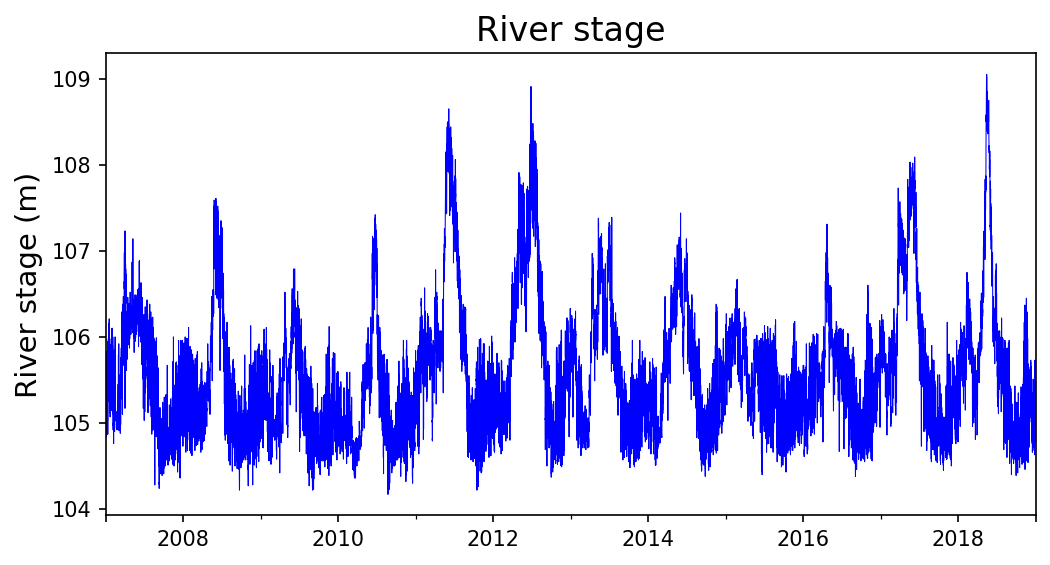

In [42]:
fname_river_stage = '/global/homes/z/zc727/HFR/data/stage_2007-2019/DatumH_River_321.txt' # '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/boundary_conditions/river_bc/stage_2007-2019/DatumH_River_321.txt'
river_stage = pd.read_csv(fname_river_stage, header = None, sep = " ", 
                          names= ['dt', 'Easting', 'Northing', 'wl'])
river_stage['datetime'] = [date_origin + timedelta(seconds = i) for i in river_stage['dt'].values]
river_stage.set_index('datetime', drop = False, inplace = True)

# for itime in tqdm(river_stage.index[::120]):

fig, ax = plt.subplots(1,1, figsize=(8,4))

river_stage.plot(y='wl', color = 'blue', ax=ax, lw=0.5, zorder=1)

#     ax.scatter(river_stage.loc[itime, 'datetime'], river_stage.loc[itime, 'wl'], 
#                     facecolors = 'red', edgecolors= 'black', s = 30, alpha = 1,zorder=2)

ax.set_ylabel('River stage (m)', fontsize = 14)
ax.set_xlabel('')
ax.set_title('River stage', fontsize=16)
ax.get_legend().remove()
ax.set_xlim(['01/01/2007','01/01/2019']) 

#     fig.savefig(fname_river_stage_plot + str(itime) + '.png', dpi=300)
#     plt.close(fig)

## plot simu vs obs head

### convert pressure to head

In [86]:
# selected_obs_wells = list(set(obs_well_list).intersection(obs_list))
# print('intersected well number: {0}'.format(len(selected_obs_wells)))
# print(selected_obs_wells)

intersected well number: 36
['Well_399-2-2', 'Well_399-4-7', 'Well_399-8-5A', 'Well_399-2-1', 'Well_399-2-32', 'Well_399-3-20', 'Well_399-5-1', 'Well_399-3-22', 'Well_399-4-11', 'Well_399-2-10', 'Well_399-3-10', 'Well_399-3-34', 'Well_399-1-11', 'Well_399-4-9', 'Well_399-1-60', 'Well_399-3-37', 'Well_399-2-5', 'Well_399-2-3', 'Well_399-1-23', 'Well_399-3-9', 'Well_399-1-21A', 'Well_399-1-21B', 'Well_399-1-32', 'Well_399-1-17A', 'Well_399-1-2', 'Well_399-1-15', 'Well_399-2-33', 'Well_399-1-10A', 'Well_399-1-12', 'Well_399-3-18', 'Well_399-3-19', 'Well_399-1-16A', 'Well_399-1-1', 'Well_399-3-21', 'Well_399-2-25', 'Well_399-1-7']


1676


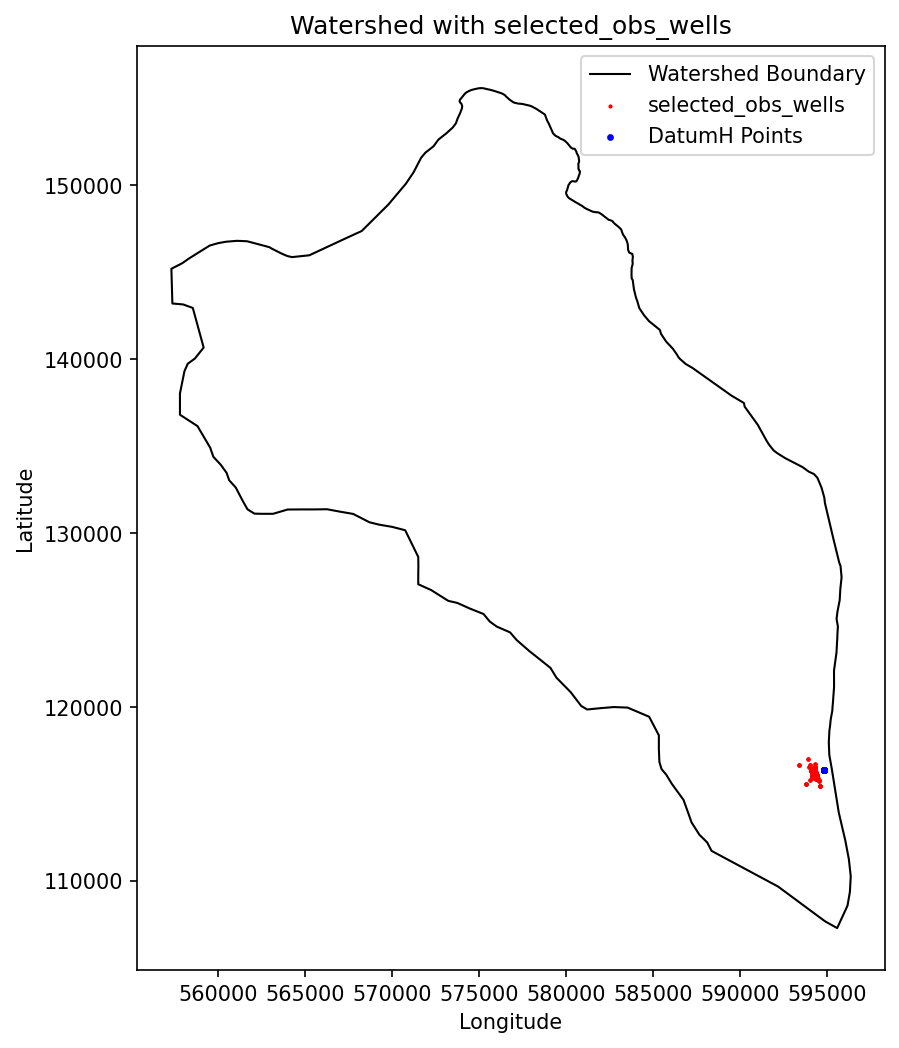

In [87]:
# # plot the location of these well in the watershed map
# watershed_shp = "/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/shapefile/boundary_poly_v5.shp"
# watershed_bound = gpd.read_file(watershed_shp)

# obs_pts_df_copy = obs_pts_df.copy()
# obs_pts_df_copy['WellName'] = None
# for iwell in obs_pts_df_copy['obs_point']:
#     if iwell.startswith('Well'):
#         iname = 'Well_'+re.split("_",iwell)[1]
#     else:
#         iname = iwell
        
#     obs_pts_df_copy.loc[obs_pts_df_copy['obs_point']==iwell,'WellName']=iname
    
# print(len(obs_pts_df_copy['WellName']))

# selected_obs_wells_df = obs_pts_df[obs_pts_df_copy['WellName'].isin(selected_obs_wells)]
# coord_xy_list = list(zip(selected_obs_wells_df['coord_x'],selected_obs_wells_df['coord_y']))

# # Convert coord_xy_list to a GeoDataFrame
# geometry = [Point(xy) for xy in coord_xy_list]
# coordinates_gdf = gpd.GeoDataFrame(geometry=geometry, crs=watershed_bound.crs)  # Assuming WGS84

# #plot the river stage as well
# coord_xy_river_stage = list(zip(river_stage['Easting'],river_stage['Northing']))
# # Convert coord_xy_list to a GeoDataFrame
# geometry = [Point(xy) for xy in coord_xy_river_stage]
# river_stage_gdf = gpd.GeoDataFrame(geometry=geometry, crs=watershed_bound.crs)  # Assuming WGS84

# # Plotting
# fig, ax = plt.subplots(figsize=(12, 8))

# # Plot the watershed boundary
# watershed_bound.boundary.plot(ax=ax, color='black', linewidth=1, label='Watershed Boundary')

# # Plot the observation well points
# coordinates_gdf.plot(ax=ax, color='red', markersize=1, label='selected_obs_wells')

# # Plot the river stage location
# river_stage_gdf.plot(ax=ax, color='blue', markersize=5, label='DatumH Points')

# # Add labels and legend
# ax.set_title('Watershed with selected_obs_wells')
# ax.set_xlabel('Longitude')
# ax.set_ylabel('Latitude')
# plt.legend()

# # Show the plot
# plt.show()


In [20]:
well_data_df.sort_index(inplace=True)

In [21]:
# iwell_name = 'Well_399-2-2'
# # iwell_name = '399-2-2'
# iwell = iwell_name

def plot_well_level(iwell, smooth_window = None, return_df = False, start_date = None, end_date = None):
    '''
    smooth_window uses rolling mean function in pandas. arguments includes: 6H, 12H, 24H...
    '''
    isimu_head = well_data_df[iwell, 'Liquid Pressure [Pa]'].copy().sort_index()
    isimu_head = (isimu_head - P_atm) / rho / g_const
    
    isimu_head.dropna(axis = 1, inplace = True)
    
    for i in isimu_head.columns:
        isimu_head.loc[:, i] = isimu_head.loc[:, i] + obs_pts_df.loc[i, 'coord_z']
    
    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_head.index])
    
    isimu_head['DateTime'] = pd.to_datetime(simu_time)
    isimu_head.set_index('DateTime', inplace=True)
    
    # iwell = "399-2-3"
    iobs_head =  obs_data_df[obs_data_df['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    # iobs_head =  obs_data_df[obs_data_df['WellName'] == iwell].sort_values(by = ['DateTime'])
    iobs_head = iobs_head[iobs_head['DateTime'].notnull()]
    iobs_head['DateTime'] = pd.to_datetime(iobs_head['DateTime'])
    iobs_head.set_index('DateTime', drop = False, inplace = True)
    iobs_head = iobs_head[['WL']].copy()

    # print(iobs_head.head())
    
    if smooth_window is not None:
        # Apply 6-hour rolling mean
        iobs_head = iobs_head.rolling(window=smooth_window).mean()
        # iobs_head = iobs_head.dropna()
    # get metrics
    metric, _ = utils.get_metrics(iobs_head.index, iobs_head['WL'].values, isimu_head.index, isimu_head.iloc[:, -1].values, 
                     metrics=['NSE', 'mKGE', 'RMSE'])
    print(metric)
    
    fig, ax = plt.subplots(1,1, figsize=(8,6))
    
    ax.plot(isimu_head.index, isimu_head.iloc[:, -1],'c-')
    ax.plot(iobs_head.index,iobs_head.loc[:, 'WL'], 'k-')

    if start_date is None:
        start_date = simu_time[0]
    if end_date is None:
        end_date = simu_time[-1]        
    
    ax.set_xlim([start_date, end_date])
    
    ax.legend(['simu_head', 'obs_head'])
    ax.set_title(f"{iwell} (NSE:{metric['NSE']:.2f}, mKGE:{metric['mKGE']:.2f}, RMSE:{metric['RMSE']:.2f})")
    ax.set_ylabel('Water table (m)')

    if return_df:
        return fig, isimu_head, iobs_head
    else:
        return fig
    
# ax.set_xlim(['2007-01-01','2009-08-01'])
# ax.set_xlim([datetime(2018,1,1, 0,0), datetime(2019,1,1, 0,0)])
# ax.set_xlim([isimu_head.index[0], isimu_head.index[-1]])
#ax.set_xlim([datetime(2007,1,1, 0,0),datetime(2008,4,6, 0,0)])

/tmp/ipykernel_1316934/1728639392.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  isimu_head = well_data_df[iwell, 'Liquid Pressure [Pa]'].copy().sort_index()


{'NSE': 0.9227241854589328, 'mKGE': 0.8867867495778201, 'RMSE': 0.20312744446156555}


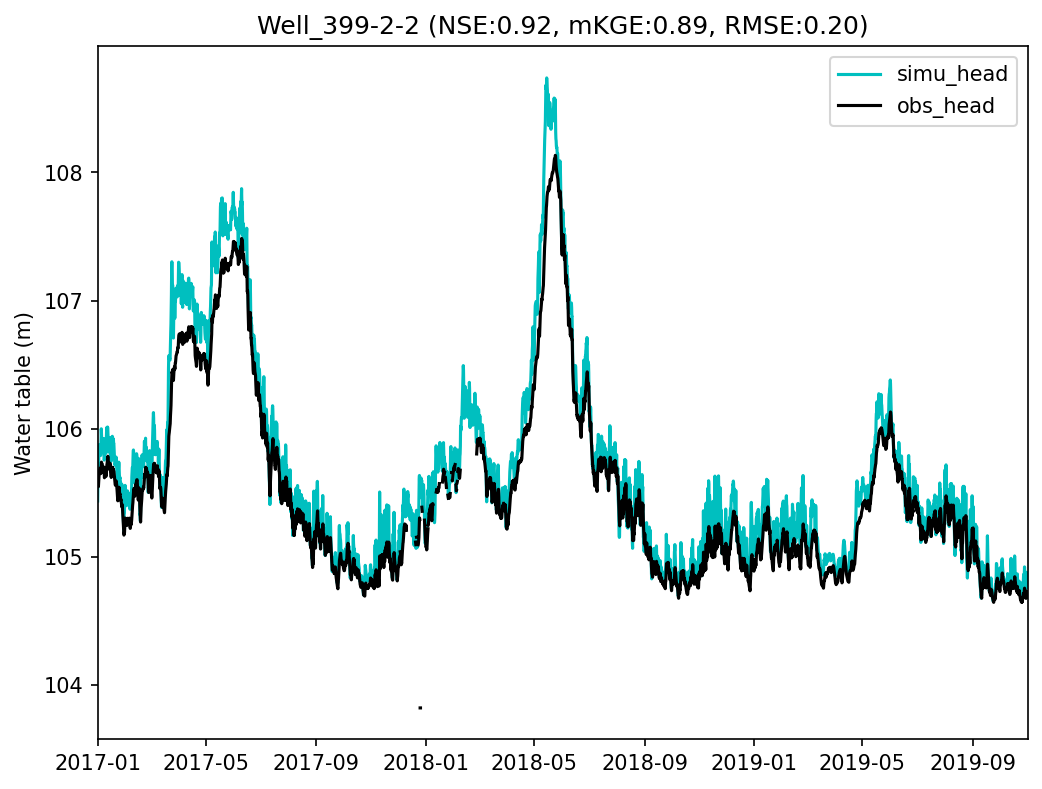

In [34]:
fig =plot_well_level('Well_399-2-2', smooth_window='6H')

{'NSE': 0.938670346961711, 'mKGE': 0.8964922927215603, 'RMSE': 0.16201715721429288}


Text(0, 0.5, 'Water table (m)')

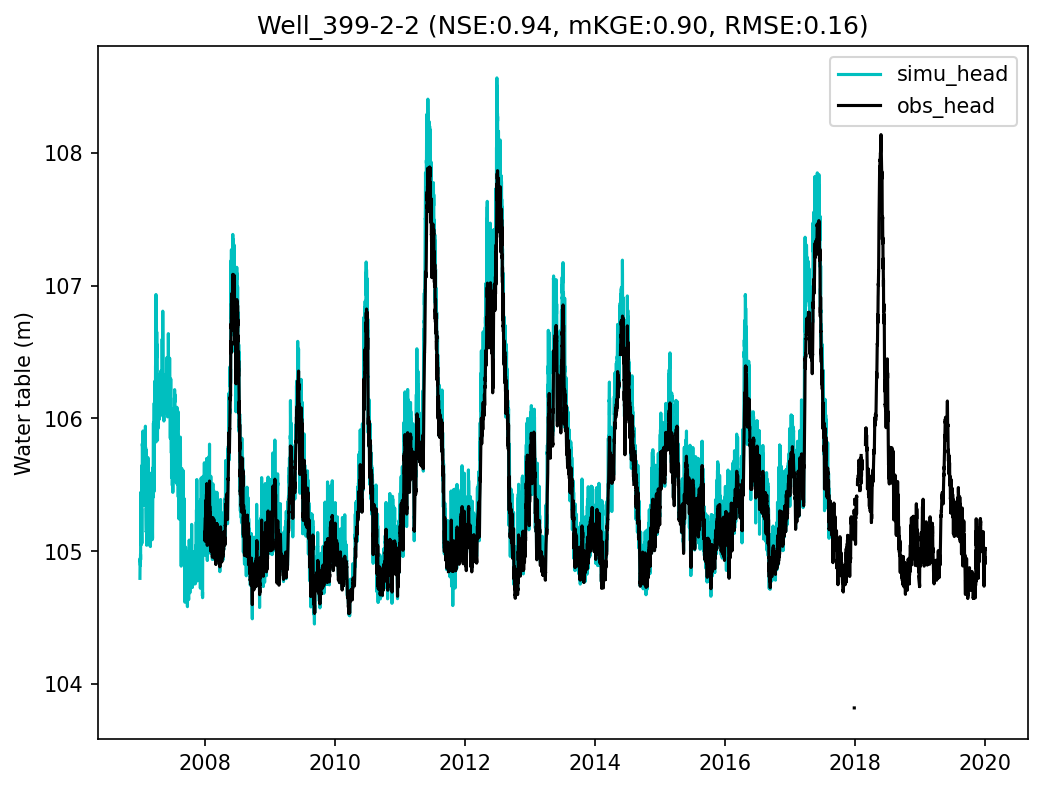

{'NSE': 0.8705832848869838, 'mKGE': 0.923819812205005, 'RMSE': 0.2347916396578902}


Text(0, 0.5, 'Water table (m)')

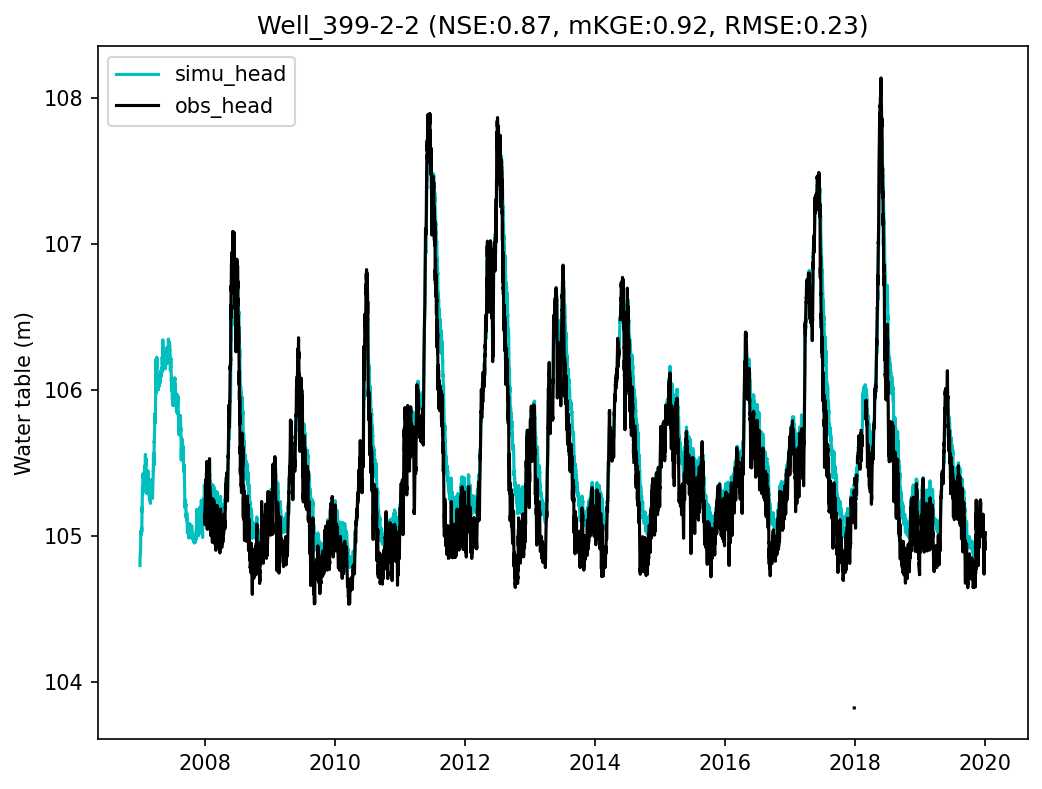

### Batch plot

In [93]:
# for iwell in tqdm(selected_obs_wells[:]):
for iwell in tqdm(well_data_df.columns.levels[0]):
#    iwell = 'Well_399-1-7'
    isimu_head = well_data_df[iwell, 'Liquid Pressure [Pa]'].copy()
    isimu_head = (isimu_head - P_atm) / rho / g_const
    isimu_head.dropna(axis = 1, inplace = True)

    for i in isimu_head.columns:
        isimu_head.loc[:, i] = isimu_head.loc[:, i] + obs_pts_df.loc[i, 'coord_z']

    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_head.index])

    isimu_head['DateTime'] = simu_time
    isimu_head.set_index('DateTime', inplace=True)

    iobs_head =  obs_data_df[obs_data_df['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    iobs_head = iobs_head[iobs_head['DateTime'].notnull()]
    iobs_head.set_index('DateTime', drop = False, inplace = True)
    
    start_window = '01/01/2011'
    end_window = '01/01/2016'

    # Convert window strings to datetime objects
    start_window_dt = datetime.strptime(start_window, '%m/%d/%Y')
    end_window_dt = datetime.strptime(end_window, '%m/%d/%Y')
    
    rmse = get_rmse(iobs_head.loc[start_window_dt:end_window_dt, 'WL'], isimu_head.loc[start_window_dt:end_window_dt, :].iloc[:, -1])
    
    fig, ax = plt.subplots(1,1, figsize=(8,5))

    ax.plot(isimu_head.index, isimu_head.iloc[:, -1], 'r', lw = 0.5)
    ax.plot(iobs_head.index,iobs_head.loc[:, 'WL'], 'k', lw = 0.5)
#    ax.set_xlim(start_window_dt, end_window_dt)
    ax.set_ylim([104, 109])
    ax.legend(['simu_head', 'obs_head'])
    ax.set_title(f"{iwell} (RMSE: {rmse})")
    ax.set_ylabel('Water table (m)')
    
#    ax.text(0.05, 0.9, "RMSE: {:.2f}".format(rmse), transform=ax.transAxes)
    
    fname_simu_obs_head = os.path.join( figure_dir, 'simu_obs_wl')
    fig.savefig(fname_simu_obs_head + '/' + 'simu_obs_'+iwell + '.jpg', dpi=150)
    plt.close(fig)
        

  0%|          | 0/62 [00:00<?, ?it/s]

Overlapping samples are fewer than 10. No RMSE is calculated!
Overlapping samples are fewer than 10. No RMSE is calculated!
Overlapping samples are fewer than 10. No RMSE is calculated!
Overlapping samples are fewer than 10. No RMSE is calculated!
Overlapping samples are fewer than 10. No RMSE is calculated!
Overlapping samples are fewer than 10. No RMSE is calculated!
Overlapping samples are fewer than 10. No RMSE is calculated!
Overlapping samples are fewer than 10. No RMSE is calculated!
Overlapping samples are fewer than 10. No RMSE is calculated!
Overlapping samples are fewer than 10. No RMSE is calculated!
Overlapping samples are fewer than 10. No RMSE is calculated!
Overlapping samples are fewer than 10. No RMSE is calculated!
Overlapping samples are fewer than 10. No RMSE is calculated!
Overlapping samples are fewer than 10. No RMSE is calculated!
Overlapping samples are fewer than 10. No RMSE is calculated!
Overlapping samples are fewer than 10. No RMSE is calculated!
Overlapp

## plot simu tracer vs. obs SpC

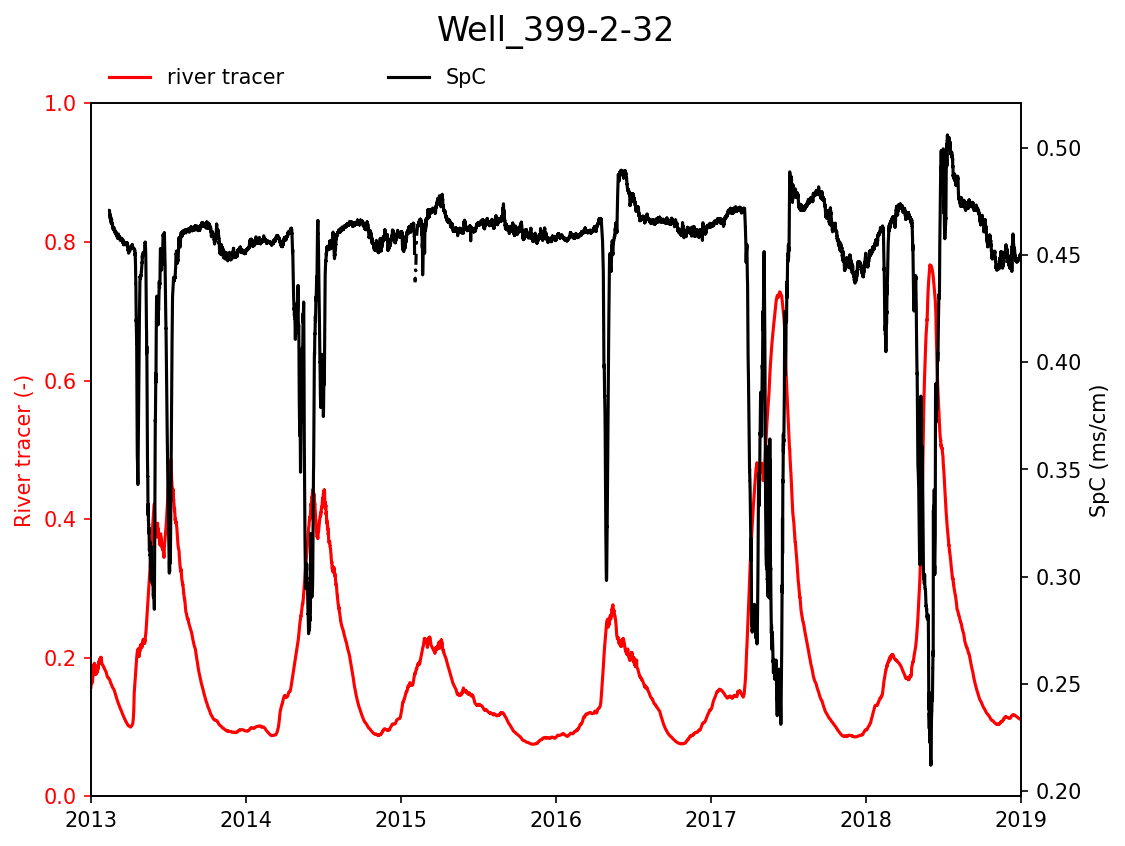

In [50]:
for iwell in selected_obs_wells[:1]:
    iwell = 'Well_399-2-32'
    isimu_df = well_data_df[iwell,'Total Tracer_river [M]', 'flux_ave_tracer'].copy()
#     isimu_head = (isimu_head - P_atm) / rho / g_const
#     isimu_head.dropna(axis = 1, inplace = True)

#     for i in isimu_df.columns:
#         isimu_head.loc[:, i] = isimu_head.loc[:, i] + obs_pts_df.loc[i, 'coord_z']

    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])

#     isimu_df['DateTime'] = simu_time
#     isimu_df.set_index('DateTime', inplace=True)
#     isimu_df.set_index(simu_time)

    iobs_df =  obs_data_df[obs_data_df['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    iobs_df = iobs_df[iobs_df['DateTime'].notnull()]
    iobs_df.set_index('DateTime', drop = False, inplace = True)

    fig, ax = plt.subplots(1,1, figsize=(8,6))

    ax.plot(simu_time, isimu_df.values, 'r-')
    
    ax11 = ax.twinx()
    ax11.plot(iobs_df.index,iobs_df.loc[:, 'SpC'], 'k-')
    ax11.set_ylabel('SpC (ms/cm)')
    ax11.legend(['SpC'],loc=[0.31, 1.01], frameon = False)
    
    start_window = '01/01/2013'
    end_window = '01/01/2019'
    
    # Convert window strings to datetime objects
    start_window_dt = datetime.strptime(start_window, '%m/%d/%Y')
    end_window_dt = datetime.strptime(end_window, '%m/%d/%Y')
    
    ax.set_xlim(start_window_dt, end_window_dt)
    ax.set_ylim([0, 1])
    ax.legend(['river tracer'],loc=[0.01, 1.01], frameon = False)
    ax.set_title(iwell, fontsize = 16, pad = 30)
    ax.set_ylabel('River tracer (-)', color = 'r')
    ax.tick_params('y', colors='r')
    
#     fig.savefig(fname_tracer_spc + iwell + '.png', dpi=300)
#     plt.close(fig)

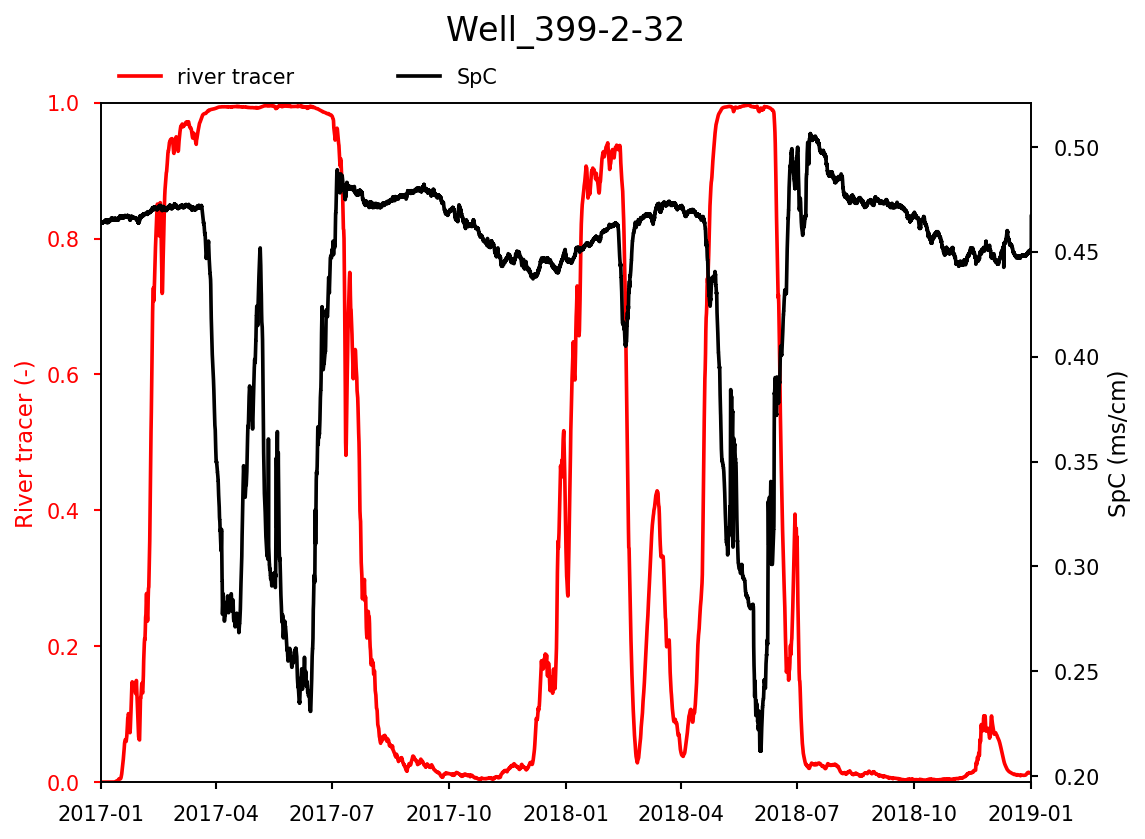

## plot tracer, head, spc all in one

  0%|          | 0/1 [00:00<?, ?it/s]

/tmp/ipykernel_602137/1365395169.py:3: PerformanceWarning: indexing past lexsort depth may impact performance.
  isimu_head = well_data_df[iwell, 'Liquid Pressure [Pa]'].copy()
/tmp/ipykernel_602137/1365395169.py:20: PerformanceWarning: indexing past lexsort depth may impact performance.
  isimu_df = well_data_df[iwell,'Total Tracer_river [M]', 'flux_ave_tracer'].copy()


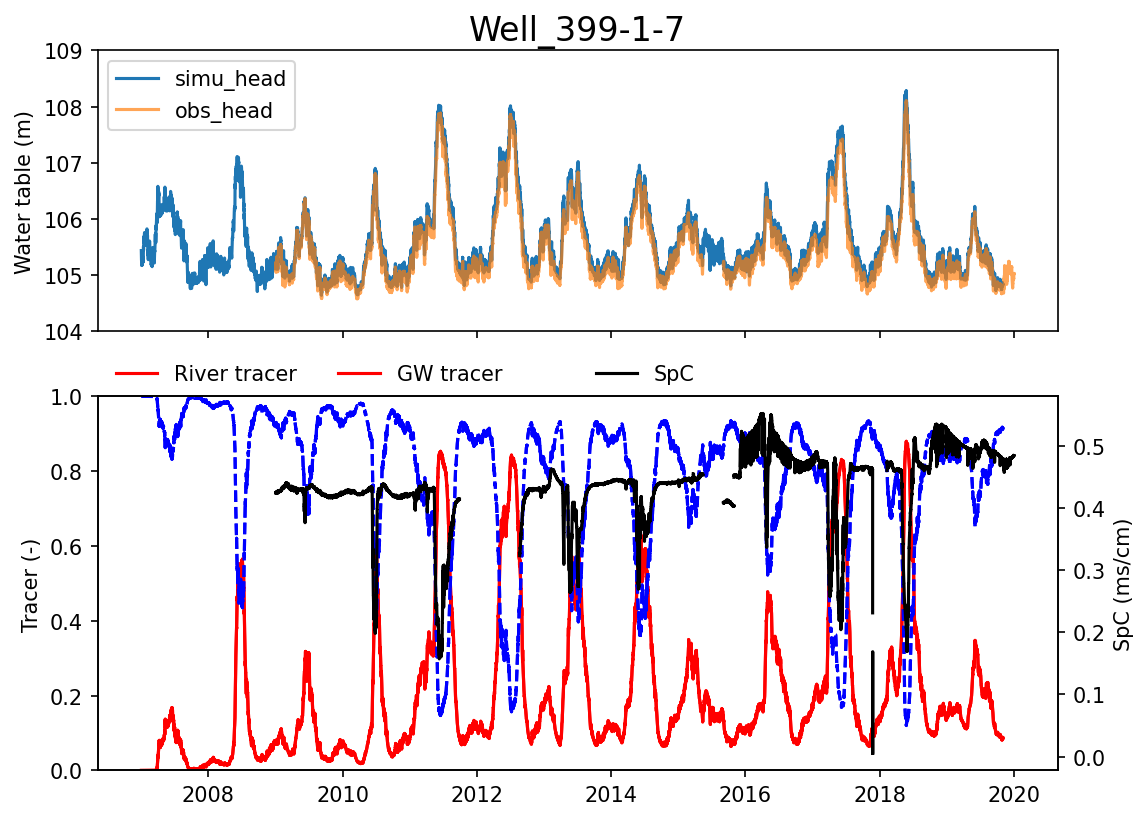

In [79]:
for iwell in tqdm(selected_obs_wells[:1]):
    iwell = 'Well_399-1-7'
    isimu_head = well_data_df[iwell, 'Liquid Pressure [Pa]'].copy()
    isimu_head = (isimu_head - P_atm) / rho / g_const
    isimu_head.dropna(axis = 1, inplace = True)

    for i in isimu_head.columns:
        isimu_head.loc[:, i] = isimu_head.loc[:, i] + obs_pts_df.loc[i, 'coord_z']

    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_head.index])

    isimu_head['DateTime'] = simu_time
    isimu_head.set_index('DateTime', inplace=True)

    iobs_head =  obs_data_df[obs_data_df['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    iobs_head = iobs_head[iobs_head['DateTime'].notnull()]
    iobs_head.set_index('DateTime', drop = False, inplace = True)
    
    
    isimu_df = well_data_df[iwell,'Total Tracer_river [M]', 'flux_ave_tracer'].copy()
#     simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])

    iobs_df =  obs_data_df[obs_data_df['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    iobs_df = iobs_df[iobs_df['DateTime'].notnull()]
    iobs_df.set_index('DateTime', drop = False, inplace = True)
    
    #------------plotting--------------#
    fig = plt.figure(figsize=(8, 6))
#     gs = gridspec.GridSpec(3, 1, height_ratios = [2, 0.5, 4])
    gs = gridspec.GridSpec(2, 1, height_ratios = [3, 4])
    gs.update(left=0.1,right=0.9,top=0.9, bottom=0.1, hspace = 0.2) # adjust vertical spacing b/w subplots

    ax1 = plt.subplot(gs[0])
    ax2 = plt.subplot(gs[1], sharex = ax1)
#     ax3 = plt.subplot(gs[1])

    ax1.plot(isimu_head.index, isimu_head.iloc[:, -1])
    ax1.plot(iobs_head.index,iobs_head.loc[:, 'WL'], alpha=0.7)
#     ax1.set_xlim(['01/01/2017', '01/01/2018'])
    ax1.set_ylim([104, 109])
    ax1.legend(['simu_head', 'obs_head'])
#     ax1.set_title(iwell)
    ax1.set_ylabel('Water table (m)')
    
    ax1.set_title(iwell, fontsize = 16, pad = 5)
    
    ax2.plot(simu_time, isimu_df.values, 'r-')
    
    # add gw tracer
    gw_tracer = 1 - isimu_df.values
    ax2.plot(simu_time, gw_tracer, 'b--')
    
    ax21 = ax2.twinx()
    ax21.plot(iobs_df.index,iobs_df.loc[:, 'SpC'], 'k-')
    ax21.set_ylabel('SpC (ms/cm)')
    
    
#     ax2.set_xlim(['01/01/2007', '01/01/2008'])
    ax2.set_ylim([0, 1])
    ax2.legend(['River tracer', 'GW tracer'],loc=[0.01, 1.01], ncol = 2, frameon = False)
#     ax2.legend(['GW tracer'],loc=[0.31, 1.01], frameon = False)
    
    ax2.set_ylabel('Tracer (-)', color = 'k')
#     ax2.tick_params('y', colors='r')
    
    ax21.legend(['SpC'],loc=[0.51, 1.01], frameon = False)
    
    plt.setp(ax1.get_xticklabels(), visible=False)
    
#     fig.savefig(fname_head_tracer_spc + iwell + '.png', dpi=300)
#     plt.close(fig)
    
    
    

/global/homes/p/pshuai/.conda/envs/widget/lib/python3.6/site-packages/IPython/core/interactiveshell.py:2858: PerformanceWarning: indexing past lexsort depth may impact performance.
  raw_cell, store_history, silent, shell_futures)


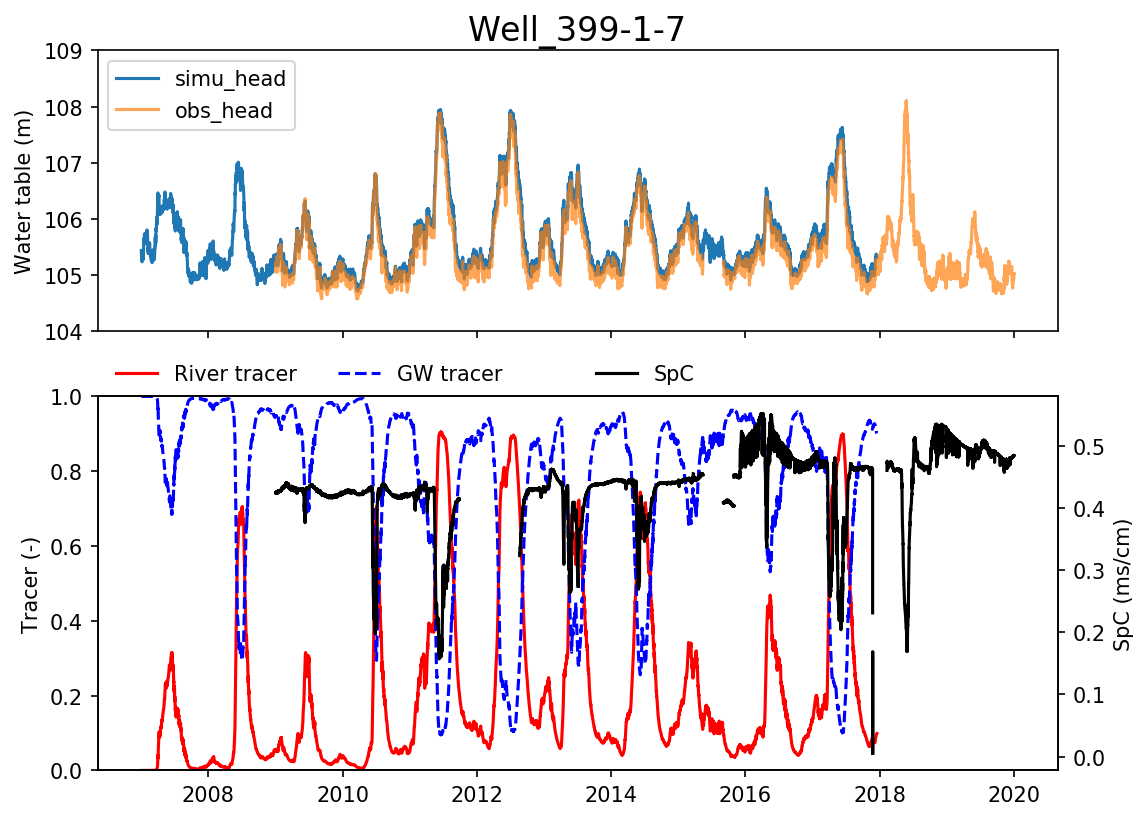

In [44]:
# figure by Shuai Pin

## plot simu vs obs temp

In [18]:
selected_obs_wells = list(set(obs_well_list).intersection(simu_well_list))

### Groundwater wells

In [38]:
def plot_well_temp(iwell, smooth_window = None, flux_average = True, return_df = False, start_date = None, end_date = None):
    
    # if flux_average:
    #     isimu_df = well_data_df[iwell,'Temperature [C]', 'flux_ave_temp'].copy()
    # else:
    isimu_df = well_data_df[iwell,'Temperature [C]'].copy()
    isimu_df = isimu_df.sort_index()
    
    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])
    
    isimu_df['DateTime'] = pd.to_datetime(simu_time)
    isimu_df.set_index('DateTime', inplace=True)

    iobs_df =  obs_data_df[obs_data_df['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    # iobs_df =  obs_data_df[obs_data_df['WellName'] == iwell].sort_values(by = ['DateTime'])
    iobs_df = iobs_df[iobs_df['DateTime'].notnull()]
    iobs_df.set_index('DateTime', drop = False, inplace = True)

    if smooth_window is not None:
        # Apply rolling mean
        iobs_df['Temp'] = iobs_df['Temp'].rolling(window=smooth_window).mean()

    # get metrics
    metric, _ = utils.get_metrics(iobs_df.index, iobs_df['Temp'].values, isimu_df.index, isimu_df.iloc[:, -1].values, 
                     metrics=['NSE', 'mKGE', 'RMSE'])
    print(metric)
    
    fig, ax = plt.subplots(1,1, figsize=(8,4))

    if flux_average:
        ax.plot(simu_time, isimu_df['flux_ave_temp'].values, 'r-')
    else:
        ax.plot(simu_time, isimu_df.iloc[:, 0], 'r-')
    #     ax11 = ax.twinx()
    ax.plot(iobs_df.index,iobs_df.loc[:, 'Temp'], 'k-')

    #     ax.legend(['simu. temp.', 'obs. temp.'],loc=[0.31, 1.01], frameon = False)

    # ax.set_xlim([isimu_df.index[0], isimu_df.index[-1]])
    # ax.set_xlim(['01/01/2007', '01/01/2009'])
    if start_date is None:
        start_date = simu_time[0]
    if end_date is None:
        end_date = simu_time[-1]        
    
    ax.set_xlim([start_date, end_date])
    ax.set_ylim([8, 20])
    ax.legend(['simu. temp.', 'obs. temp.'],loc='best', frameon = False)
    # ax.set_title(iwell, fontsize = 16)
    ax.set_title(f"{iwell} (NSE:{metric['NSE']:.2f}, mKGE:{metric['mKGE']:.2f}, RMSE:{metric['RMSE']:.2f})")

    ax.set_ylabel('Temp (${\degree}C$)')    
    
    if return_df:
        return fig, isimu_df, iobs_df
    else:
        return fig

/tmp/ipykernel_1316934/1036885857.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  isimu_df = well_data_df[iwell,'Temperature [C]'].copy()


{'NSE': 0.22440868034357742, 'mKGE': 0.5421430272244097, 'RMSE': 1.8413405855817528}


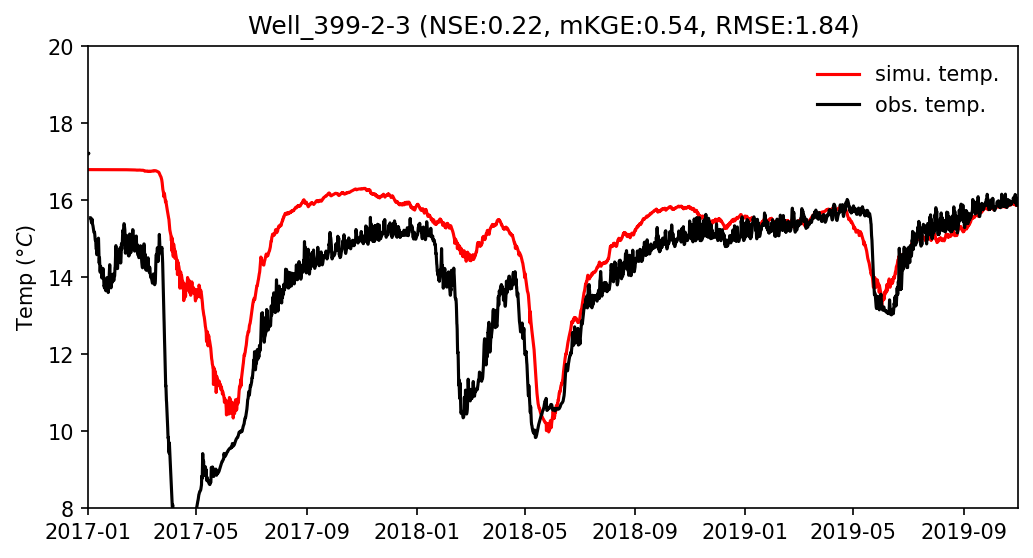

In [39]:
fig, isimu_df, iobs_df = plot_well_temp(iwell = 'Well_399-2-3', smooth_window='6H', flux_average=True, return_df=True)

/tmp/ipykernel_3922/3542505956.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  isimu_df = well_data_df[iwell,'Temperature [C]'].copy()


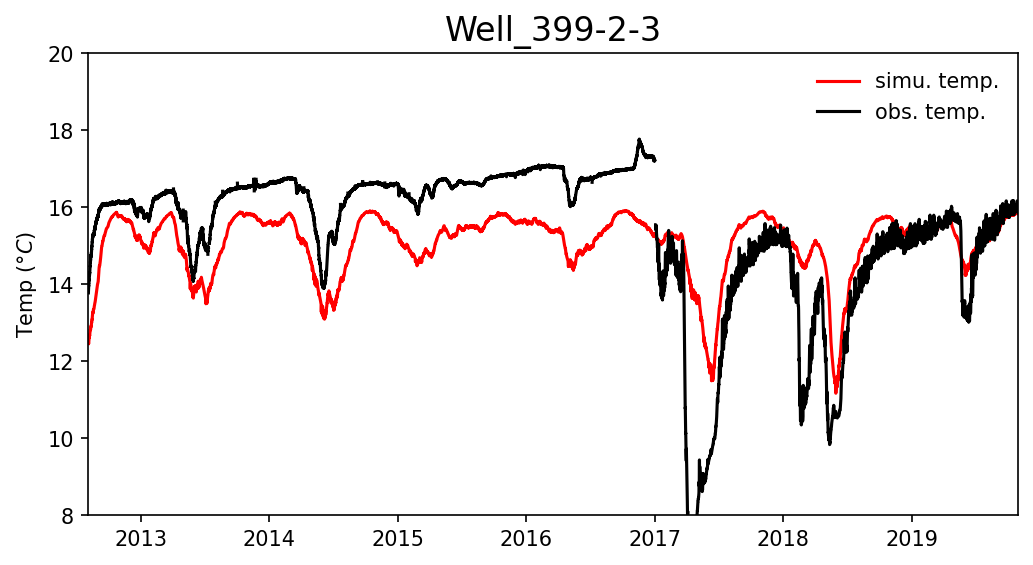

/tmp/ipykernel_1316934/1036885857.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  isimu_df = well_data_df[iwell,'Temperature [C]'].copy()


{'NSE': -0.1936937419353344, 'mKGE': 0.8215333177128296, 'RMSE': 1.8398082282887378}


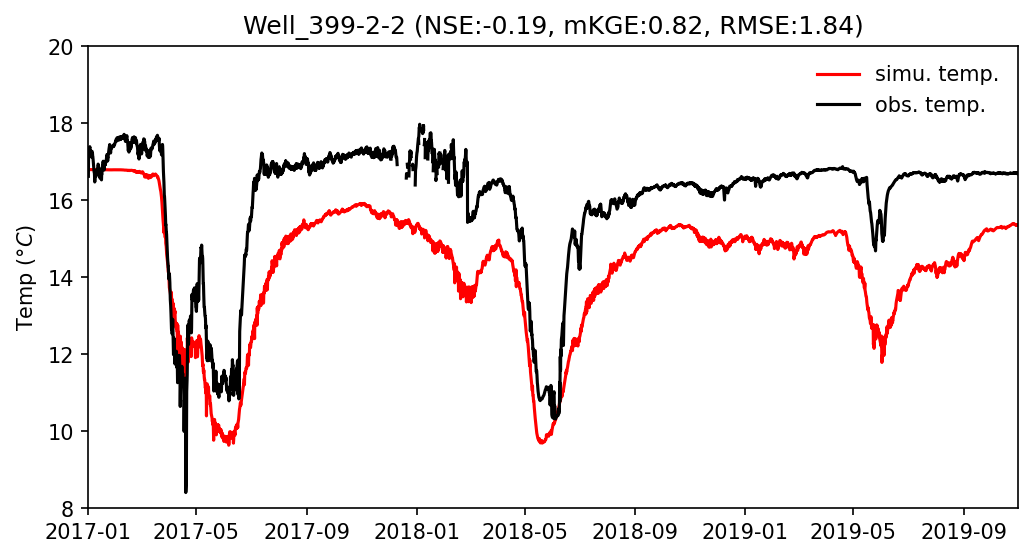

In [40]:
fig = plot_well_temp(iwell = 'Well_399-2-2', smooth_window='6H', flux_average=True)

/tmp/ipykernel_3922/3542505956.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  isimu_df = well_data_df[iwell,'Temperature [C]'].copy()


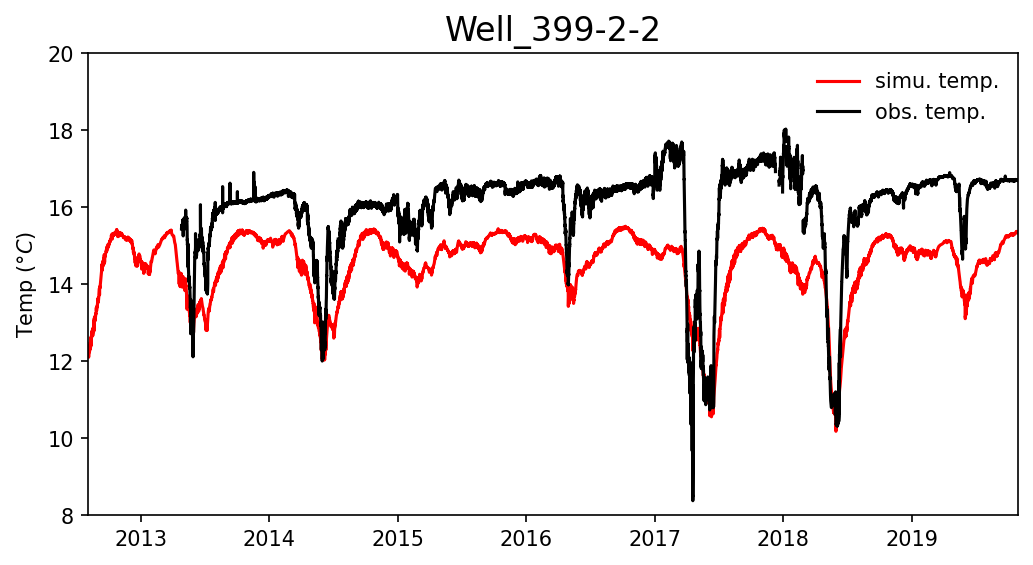

In [17]:
fig = plot_well_temp(iwell = 'Well_399-2-2', flux_average=True)

### batch plot

In [ ]:
for iwell in selected_obs_wells:
    # fig = plot_well_temp(iwell)   
    try:
        fig = plot_well_temp(iwell, flux_average=True)
    except:
        pass
    
    fig.savefig(figure_dir + f"{case_name}simu_obs_temp/" + iwell + '_2019.jpg', dpi=300)
    plt.close(fig)

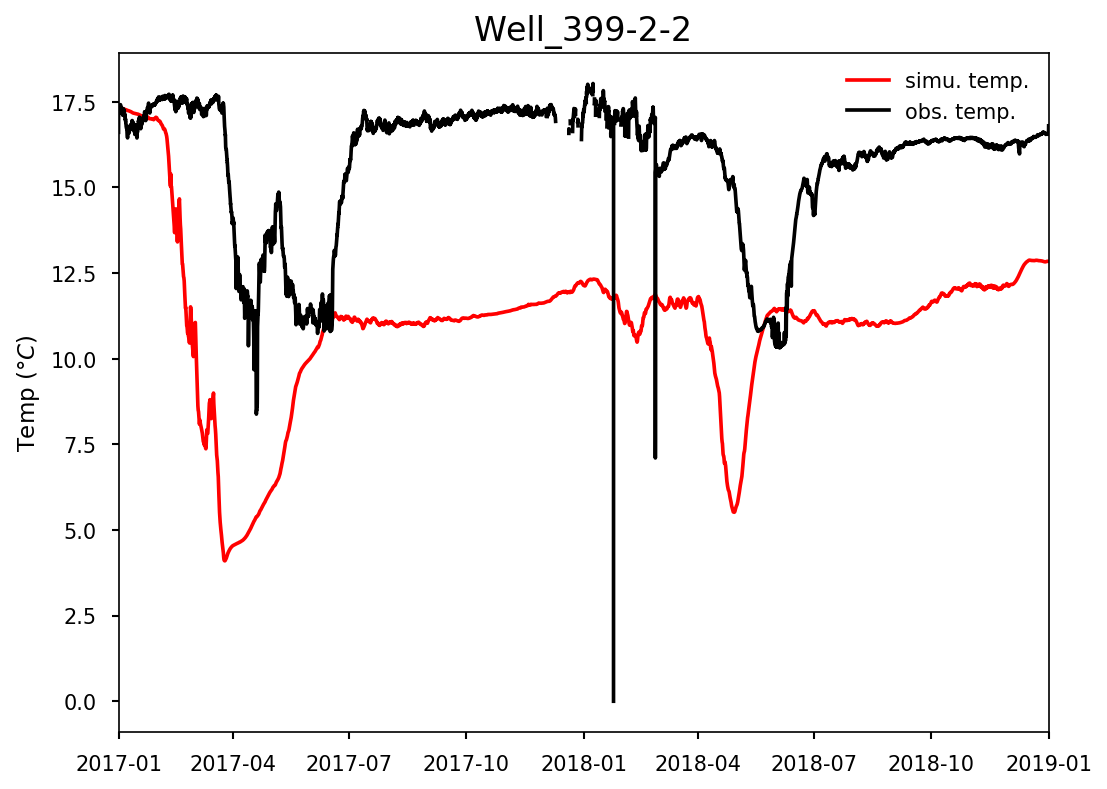

#### all in one

In [93]:
well_list = [ 'Well_399-2-2','Well_399-1-16A','Well_399-1-21A','Well_399-1-7','Well_399-2-32','Well_399-2-3','Well_399-2-1']

/global/homes/p/pshuai/.conda/envs/geo/lib/python3.9/site-packages/IPython/core/interactiveshell.py:2894: PerformanceWarning: indexing past lexsort depth may impact performance.
  result = self._run_cell(
/global/homes/p/pshuai/.conda/envs/geo/lib/python3.9/site-packages/IPython/core/interactiveshell.py:2894: PerformanceWarning: indexing past lexsort depth may impact performance.
  result = self._run_cell(
/global/homes/p/pshuai/.conda/envs/geo/lib/python3.9/site-packages/IPython/core/interactiveshell.py:2894: PerformanceWarning: indexing past lexsort depth may impact performance.
  result = self._run_cell(
/global/homes/p/pshuai/.conda/envs/geo/lib/python3.9/site-packages/IPython/core/interactiveshell.py:2894: PerformanceWarning: indexing past lexsort depth may impact performance.
  result = self._run_cell(
/global/homes/p/pshuai/.conda/envs/geo/lib/python3.9/site-packages/IPython/core/interactiveshell.py:2894: PerformanceWarning: indexing past lexsort depth may impact performance.
  

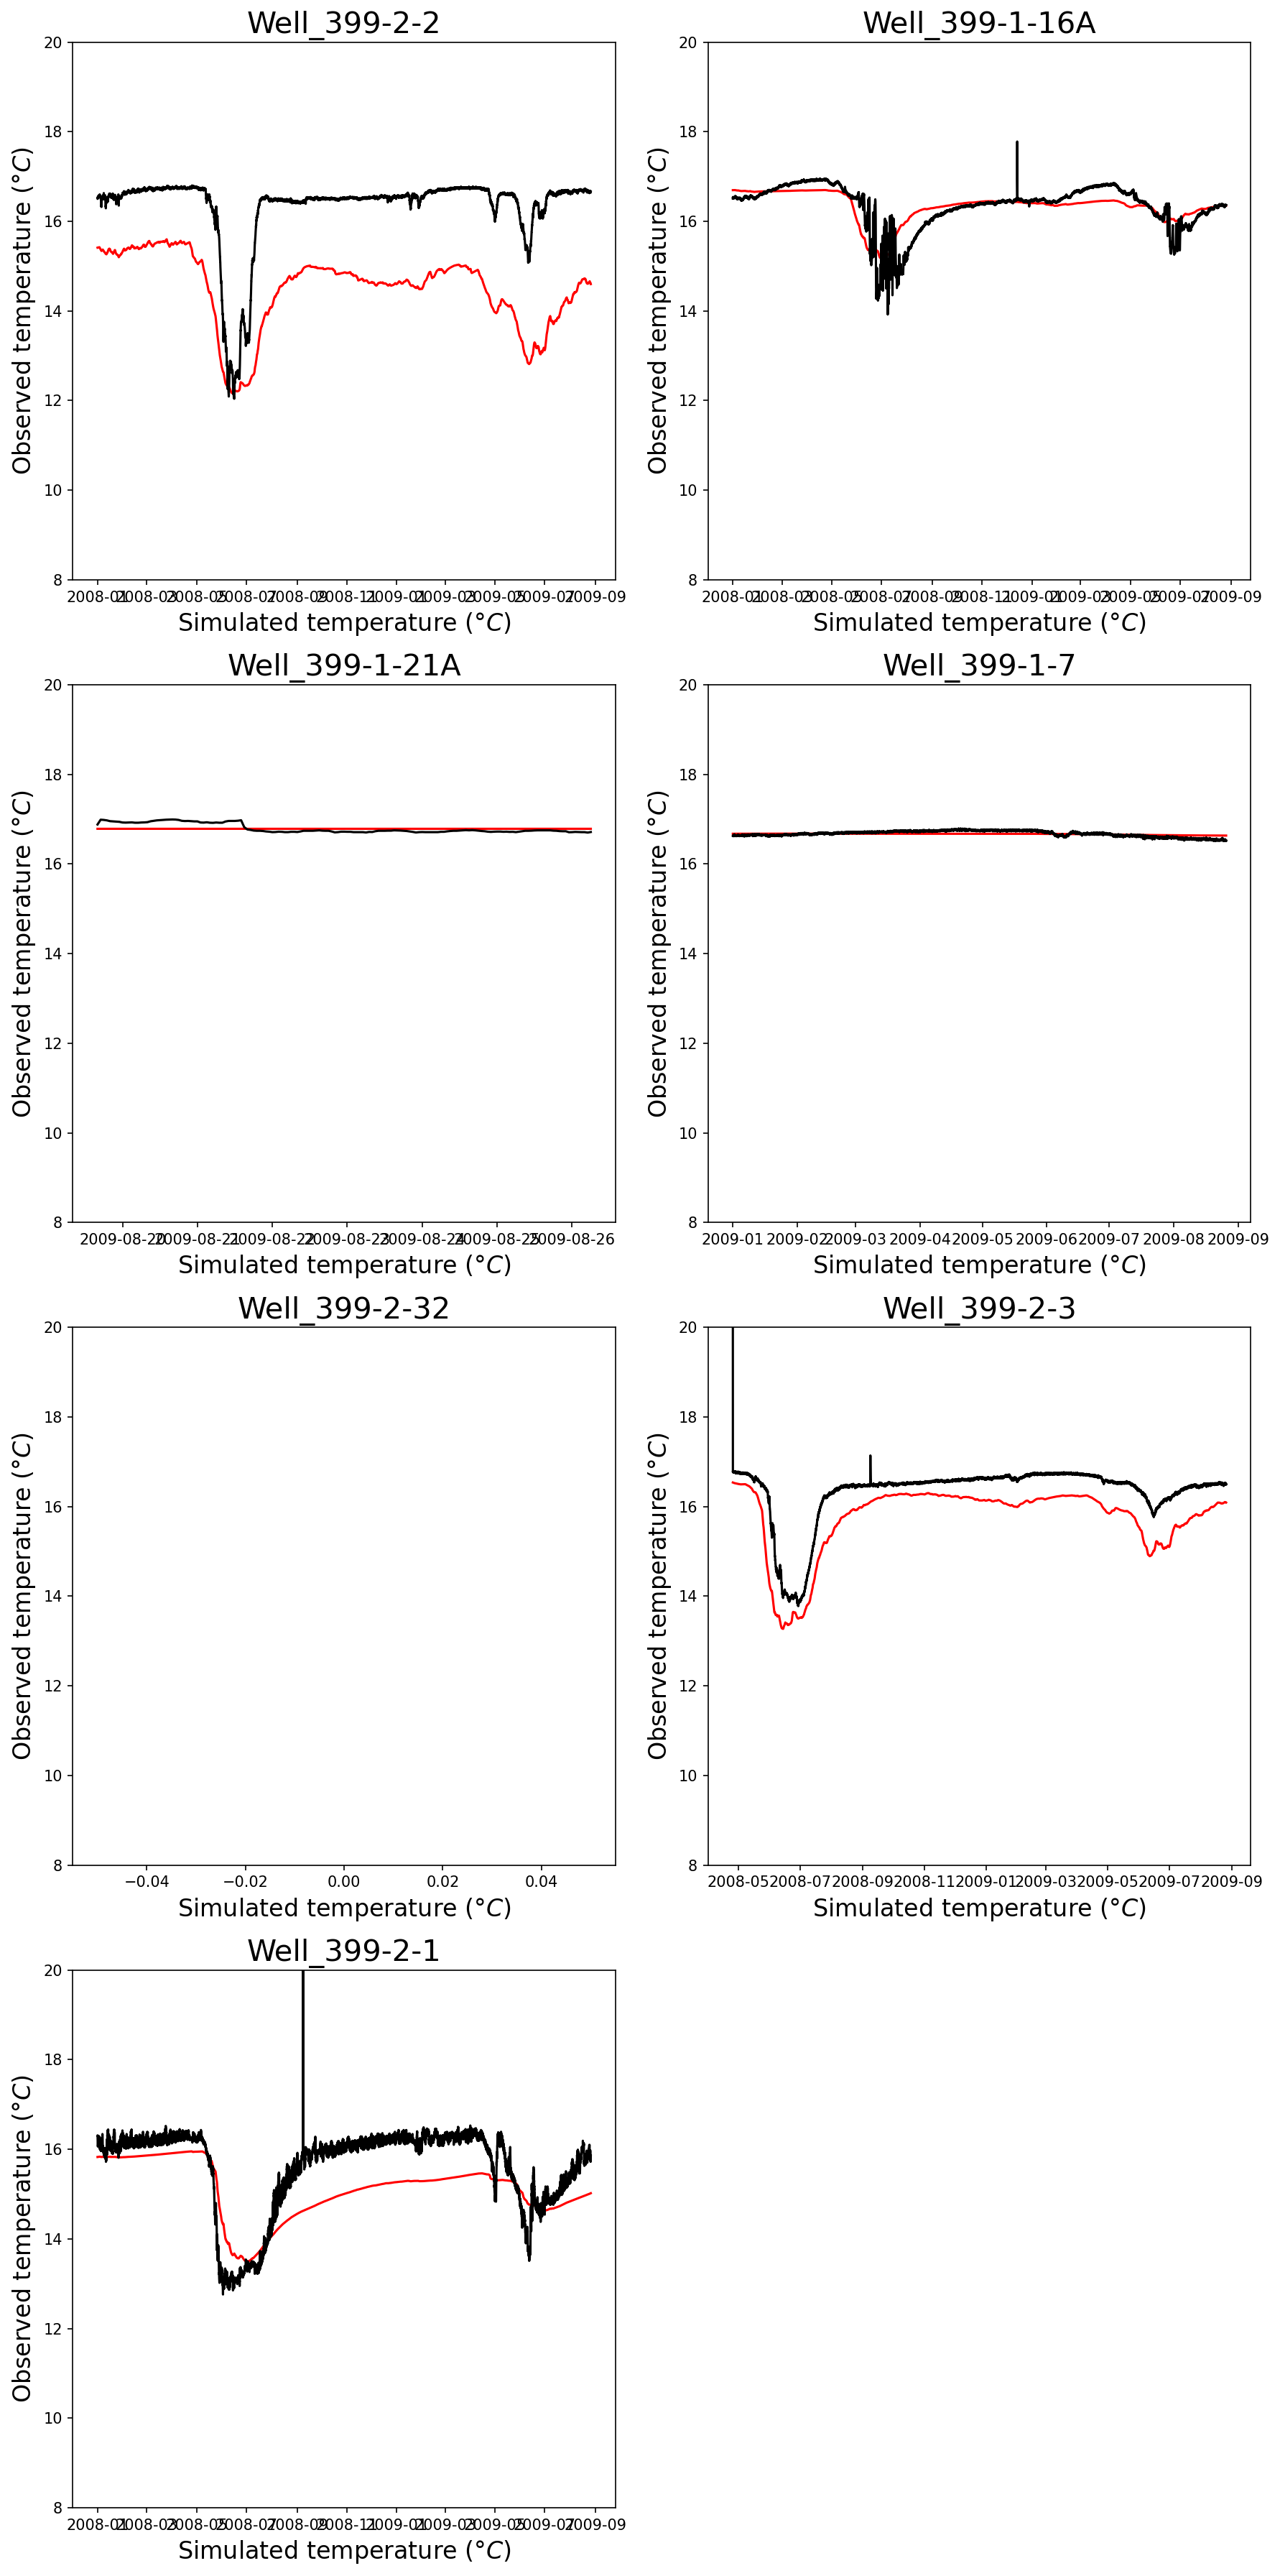

In [118]:
fig, axes = plt.subplots(4, 2, figsize = (12, 24))

for iwell, ax in zip(well_list, axes.flatten()[:-1]):
#     iwell = 'Well_399-2-2'
    isimu_head = well_data_df[iwell, 'Temperature [C]'].copy()
#     isimu_head = (isimu_head - P_atm) / rho / g_const
    isimu_head.dropna(axis = 1, inplace = True)

#     for i in isimu_head.columns:
#         isimu_head.loc[:, i] = isimu_head.loc[:, i] + obs_pts_df.loc[i, 'coord_z']

    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_head.index])

    isimu_head['DateTime'] = simu_time
    isimu_head.set_index('DateTime', inplace=True)

    iobs_head =  obs_data_df[obs_data_df['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    iobs_head = iobs_head[iobs_head['DateTime'].notnull()]
    iobs_head.set_index('DateTime', drop = False, inplace = True)
    
    merged_df = pd.merge(isimu_head, iobs_head, right_on = iobs_head.index ,left_index = True)
    merged_df.dropna(subset=[f'{iwell}_1', "Temp"], inplace=True)
    # rmse = mean_squared_error(merged_df.loc[:, f'{iwell}_1'], merged_df.loc[:, 'Temp'])**0.5
#     fig, ax = plt.subplots(1,1, figsize=(6,6))
    ax.plot(merged_df.index, merged_df.loc[:, f'{iwell}_1'], 'r-')
    ax.plot(merged_df.index,merged_df.loc[:, 'Temp'], 'k-')
#     sns.scatterplot(data = merged_df, x = f'{iwell}_1', y = "Temp", ax = ax)
#     ax.plot([0, 1], [0, 1], color='red', transform=ax.transAxes)
    # ax.text(0.7, 0.92, 'RMSE = {0:.2f}'.format(rmse), fontweight= 'bold',
    #      fontsize = 16, color = 'k', transform = ax.transAxes)
    
    ax.set_ylim([8, 20])
#     ax.legend(['simu_head', 'obs_head'])
    ax.set_title(iwell, fontsize = 20)
    ax.set_ylabel('Observed temperature (${\degree}C$)', fontsize = 16)
    ax.set_xlabel('Simulated temperature (${\degree}C$)', fontsize = 16)
    ax.set_aspect('auto')
    

axes[-1, -1].axis('off')
fig.tight_layout()

In [97]:
fig.savefig(out_dir + 'scatterplots/temp_allinone.png', dpi=300)
plt.close(fig)

#### one2one plot

In [34]:
well_list = [ 'Well_399-2-2','Well_399-1-16A','Well_399-1-21A','Well_399-1-7','Well_399-2-32','Well_399-2-3','Well_399-2-1']

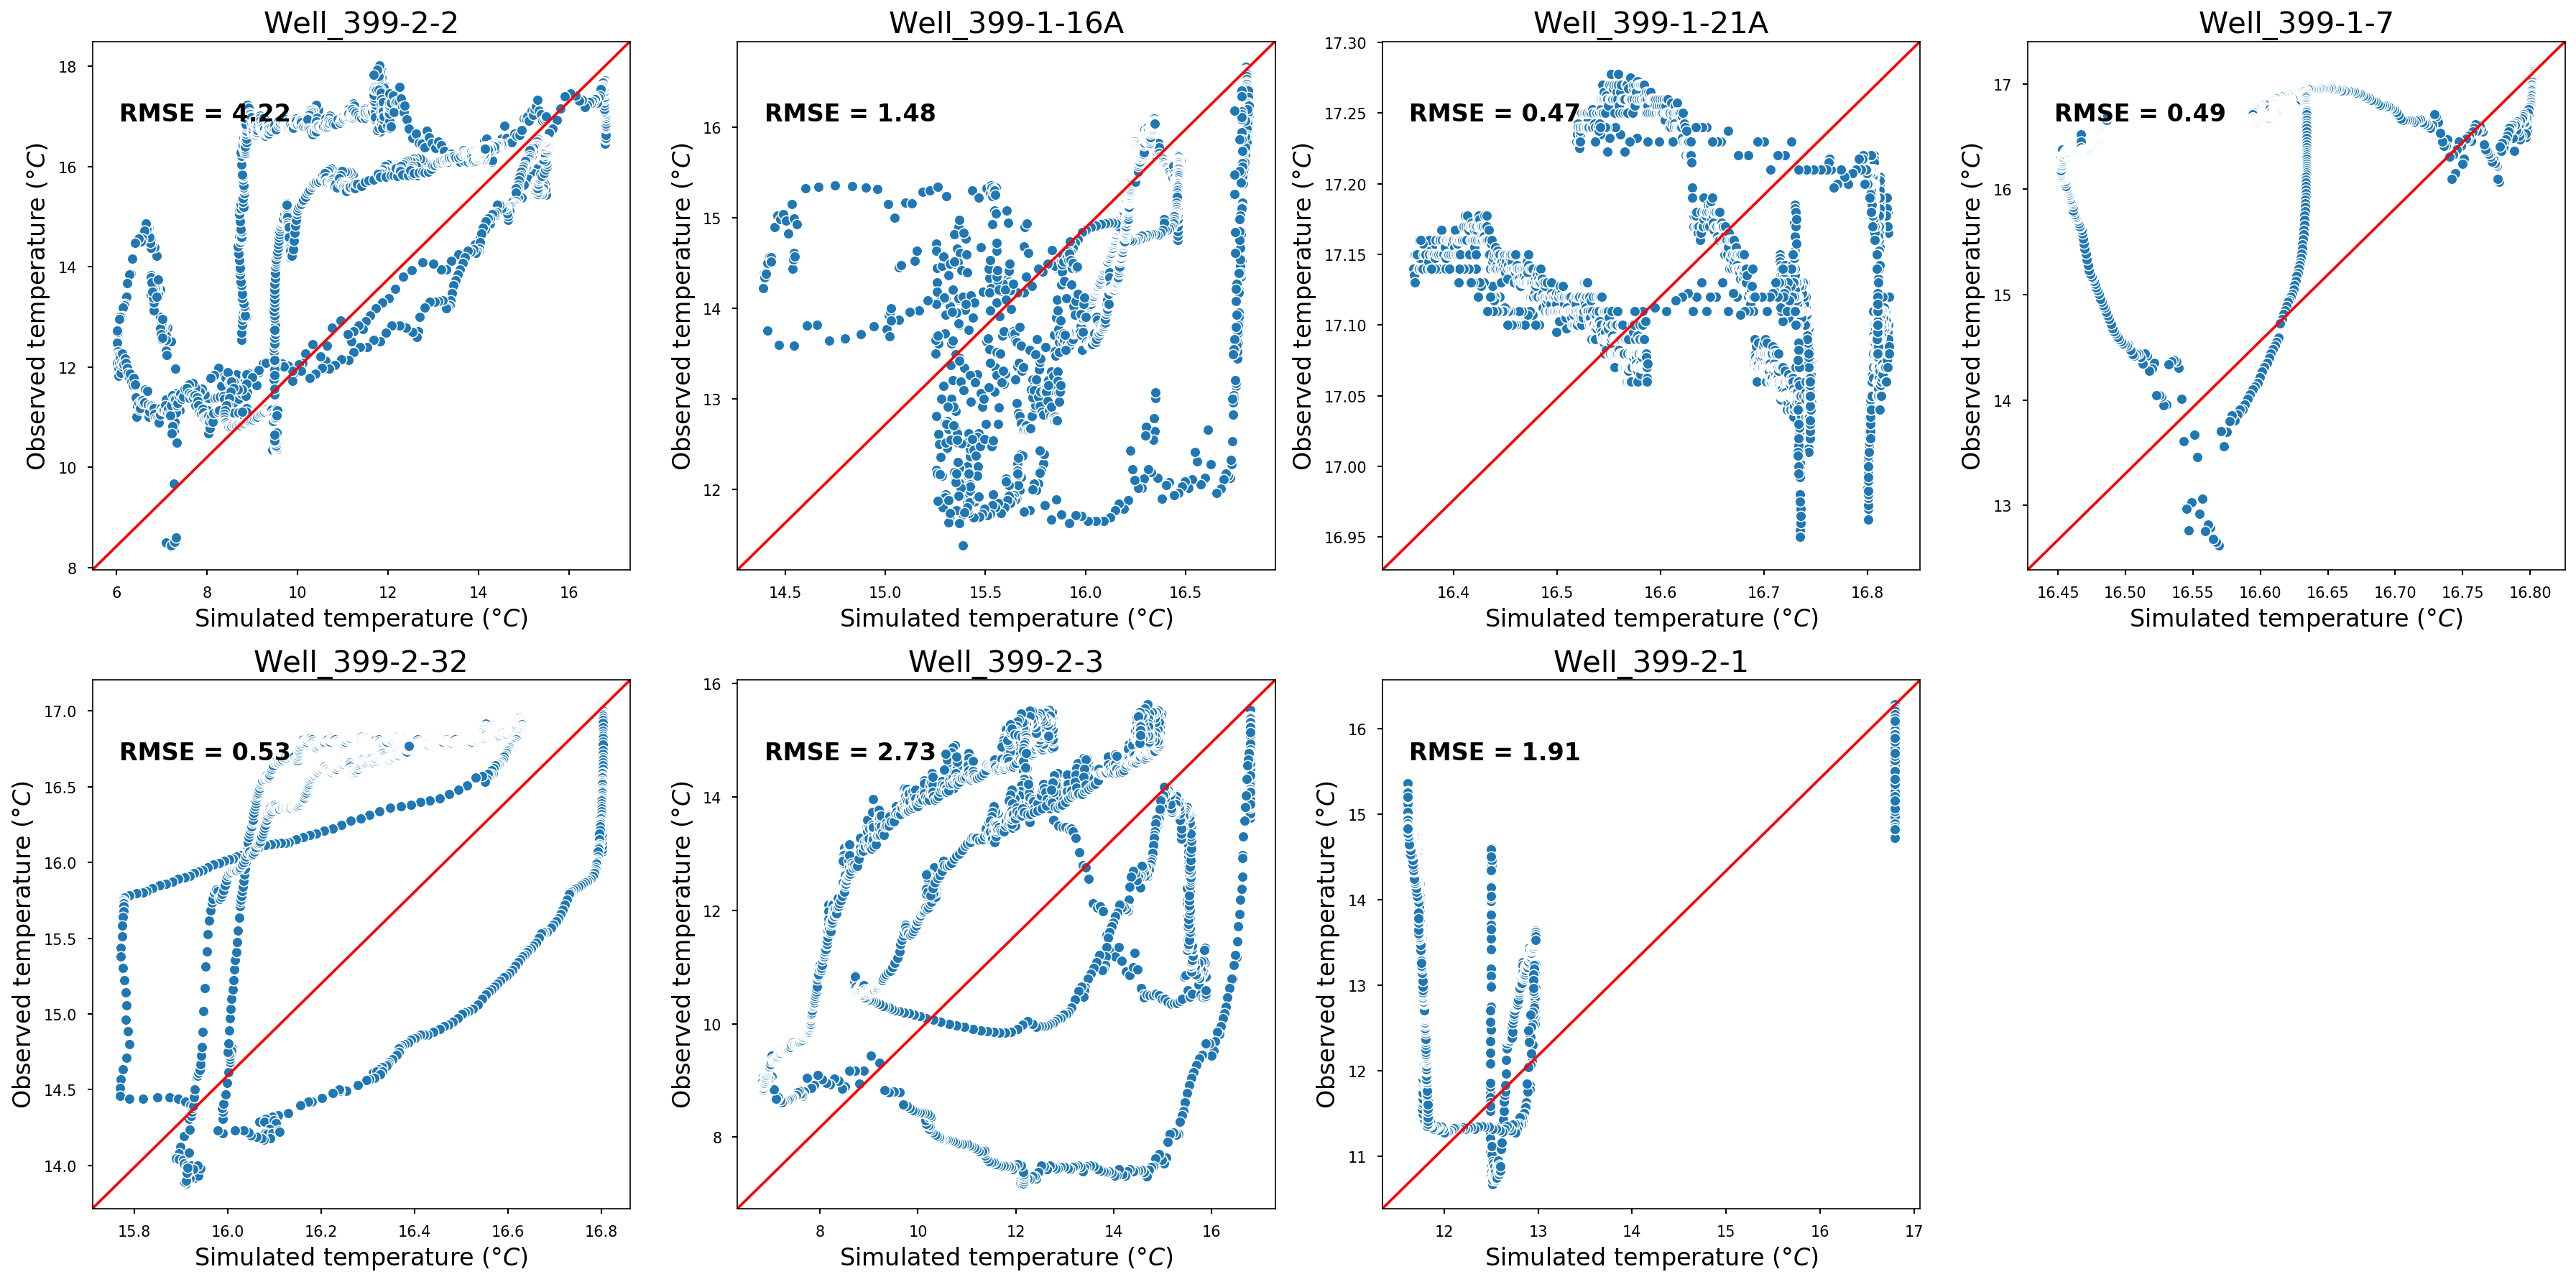

In [92]:
fig, axes = plt.subplots(2, 4, figsize = (24, 12))

for iwell, ax in zip(well_list, axes.flatten()[:-1]):
#     iwell = 'Well_399-2-2'
    isimu_head = well_data_df[iwell, 'Temperature [C]'].copy()
#     isimu_head = (isimu_head - P_atm) / rho / g_const
    isimu_head.dropna(axis = 1, inplace = True)

#     for i in isimu_head.columns:
#         isimu_head.loc[:, i] = isimu_head.loc[:, i] + obs_pts_df.loc[i, 'coord_z']

    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_head.index])

    isimu_head['DateTime'] = simu_time
    isimu_head.set_index('DateTime', inplace=True)

    iobs_head =  obs_data_df[obs_data_df['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    iobs_head = iobs_head[iobs_head['DateTime'].notnull()]
    iobs_head.set_index('DateTime', drop = False, inplace = True)
    
    merged_df = pd.merge(isimu_head, iobs_head, right_on = iobs_head.index ,left_index = True)
    merged_df.dropna(subset=[f'{iwell}_1', "Temp"], inplace=True)
    rmse = mean_squared_error(merged_df.loc[:, f'{iwell}_1'], merged_df.loc[:, 'Temp'])**0.5
#     fig, ax = plt.subplots(1,1, figsize=(6,6))

    sns.scatterplot(data = merged_df, x = f'{iwell}_1', y = "Temp", ax = ax)
    ax.plot([0, 1], [0, 1], color='red', transform=ax.transAxes)
    ax.text(0.05, 0.85, 'RMSE = {0:.2f}'.format(rmse), fontweight= 'bold',
         fontsize = 16, color = 'k', transform = ax.transAxes)
    
#     ax.set_ylim([0, 24])
#     ax.legend(['simu_head', 'obs_head'])
    ax.set_title(iwell, fontsize = 20)
    ax.set_ylabel('Observed temperature (${\degree}C$)', fontsize = 16)
    ax.set_xlabel('Simulated temperature (${\degree}C$)', fontsize = 16)
    ax.set_aspect('auto')
    

axes[-1, -1].axis('off')
fig.tight_layout()

In [89]:
fig.savefig(out_dir + 'scatterplots/wl_one2one.png', dpi=300)
plt.close(fig)

### thermistors

#### **Dense Array**

In [41]:
piezometer_list = [i for i in well_data_df.columns.levels[0] if "Well_" not in i]

In [42]:
DA_wells = [i for i in piezometer_list if i.startswith('T')]

In [43]:
DA_T = pd.read_csv(fname_DA_T, na_values = ['NA', 'NAN'])
DA_T = insertNA(DA_T, 'TIMESTAMP')
DA_T.set_index('TIMESTAMP', drop = False, inplace = True)

In [95]:
def plot_DA_temp(iwell, smooth_window = None, flux_average = True, return_df = False, start_date = None, end_date = None):
    
    iwell_id = well_screen[well_screen['WellName'] == iwell]['Well_ID'].values[0]

    iobs_df = DA_T.loc[:, iwell_id.replace('(', '.').replace(')', '.')].copy()
    # use 6-hr smoothing for observationd data (5 min freq)
    if smooth_window is not None:
        iobs_df = iobs_df.resample(smooth_window).mean()
    iobs_df[iobs_df < 0] = np.nan
    # iobs_smooth = iobs_df.resample('6H', offset='3H').mean()
    isimu_df = well_data_df.loc[:, [(iwell,'Temperature [C]', 'flux_ave_temp')]].copy()
    
    # isimu_df = well_data_df[iwell,'Temperature [C]'].copy()
    # isimu_df = isimu_df.sort_index()
    
    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])
    
    isimu_df['DateTime'] = pd.to_datetime(simu_time)
    isimu_df.set_index('DateTime', inplace=True)

    # iobs_df =  obs_data_df[obs_data_df['WellName'] == iwell.replace('Well_', '')].sort_values(by = ['DateTime'])
    # # iobs_df =  obs_data_df[obs_data_df['WellName'] == iwell].sort_values(by = ['DateTime'])
    # iobs_df = iobs_df[iobs_df['DateTime'].notnull()]
    # iobs_df.set_index('DateTime', drop = False, inplace = True)

    # if smooth_window is not None:
    #     # Apply rolling mean
    #     iobs_df = iobs_df.rolling(window=smooth_window).mean()

    # get metrics
    metric, _ = utils.get_metrics(iobs_df.index, iobs_df.values, isimu_df.index, isimu_df.iloc[:, -1].values, 
                     metrics=['NSE', 'mKGE', 'RMSE'])
    print(metric)
    
    fig, ax = plt.subplots(1,1, figsize=(8,4))

    ax.plot(iobs_df.index,iobs_df.values, 'k-')
    if flux_average:
        ax.plot(simu_time, isimu_df.iloc[:, -1], 'r-')
    else:
        ax.plot(simu_time, isimu_df.iloc[:, 0], 'r-')
    #     ax11 = ax.twinx()


    #     ax.legend(['simu. temp.', 'obs. temp.'],loc=[0.31, 1.01], frameon = False)

    # ax.set_xlim([isimu_df.index[0], isimu_df.index[-1]])
    # ax.set_xlim(['01/01/2007', '01/01/2009'])
    if start_date is None:
        start_date = simu_time[0]
    if end_date is None:
        end_date = simu_time[-1]        
    
    ax.set_xlim([start_date, end_date])
    ax.set_ylim([0, 24])
    ax.legend(['simu. temp.', 'obs. temp.'],loc='best', frameon = False)
    # ax.set_title(iwell, fontsize = 16)
    ax.set_title(f"{iwell} (NSE:{metric['NSE']:.2f}, mKGE:{metric['mKGE']:.2f}, RMSE:{metric['RMSE']:.2f})", fontsize=16)
    ax.set_ylabel('Temperature $(^{\circ}C)$', fontsize=16)
    # ax.set_ylabel('Temp (${\degree}C$)')    
    
    if return_df:
        return fig, isimu_df, iobs_df
    else:
        return fig

{'NSE': 0.6912668204949215, 'mKGE': 0.7467434244537474, 'RMSE': 1.8586778722709911}


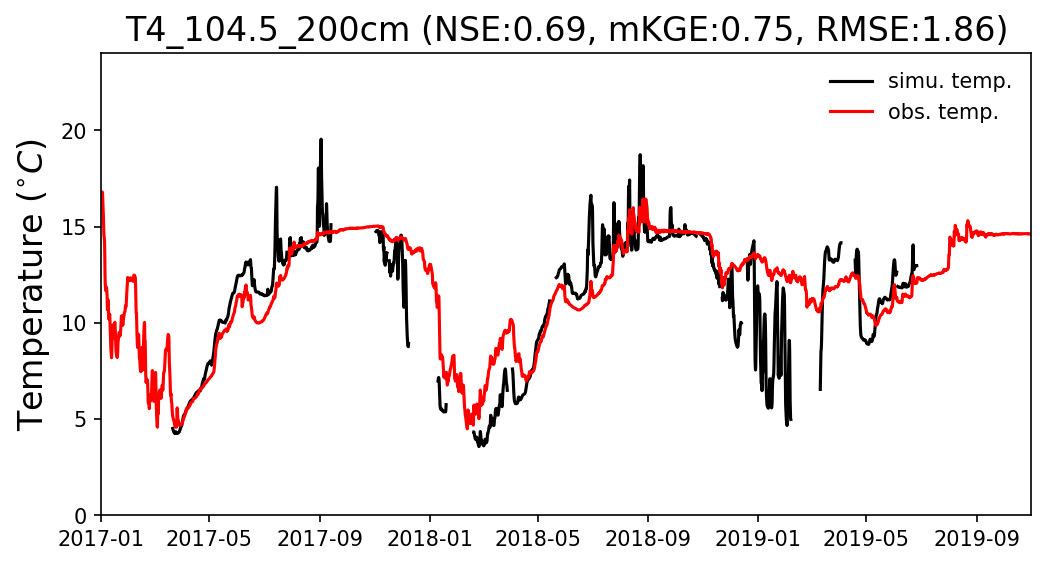

In [96]:
fig, isimu_df, iobs_df = plot_DA_temp(iwell = 'T4_104.5_200cm', smooth_window='6H', flux_average=True, return_df=True)

{'NSE': 0.7681622721195147, 'mKGE': 0.8563414841899127, 'RMSE': 2.0827357467136394}


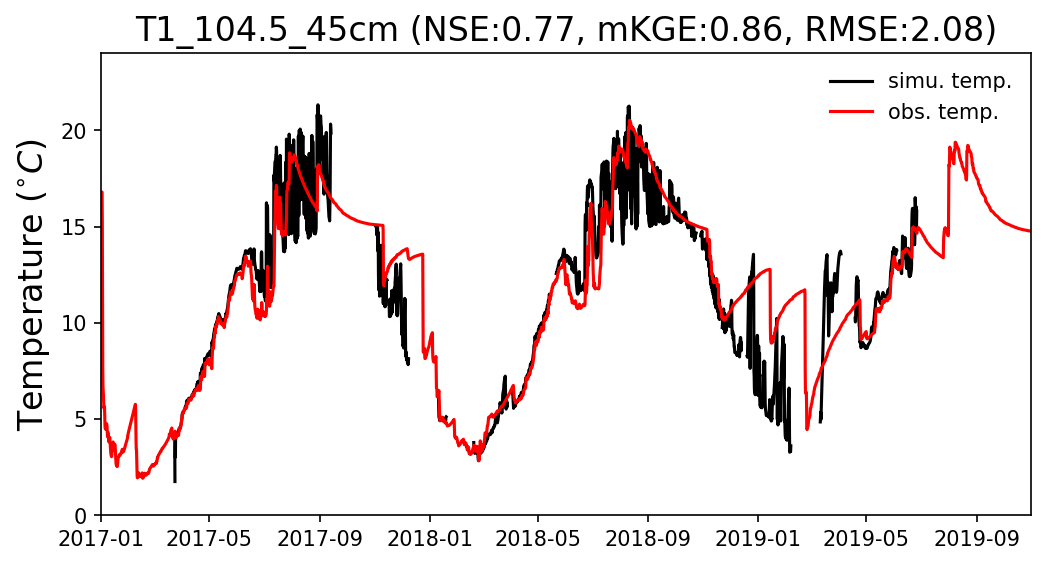

In [97]:
fig, isimu_df, iobs_df = plot_DA_temp(iwell = 'T1_104.5_45cm', smooth_window='6H', flux_average=True, return_df=True)

  0%|          | 0/1 [00:00<?, ?it/s]

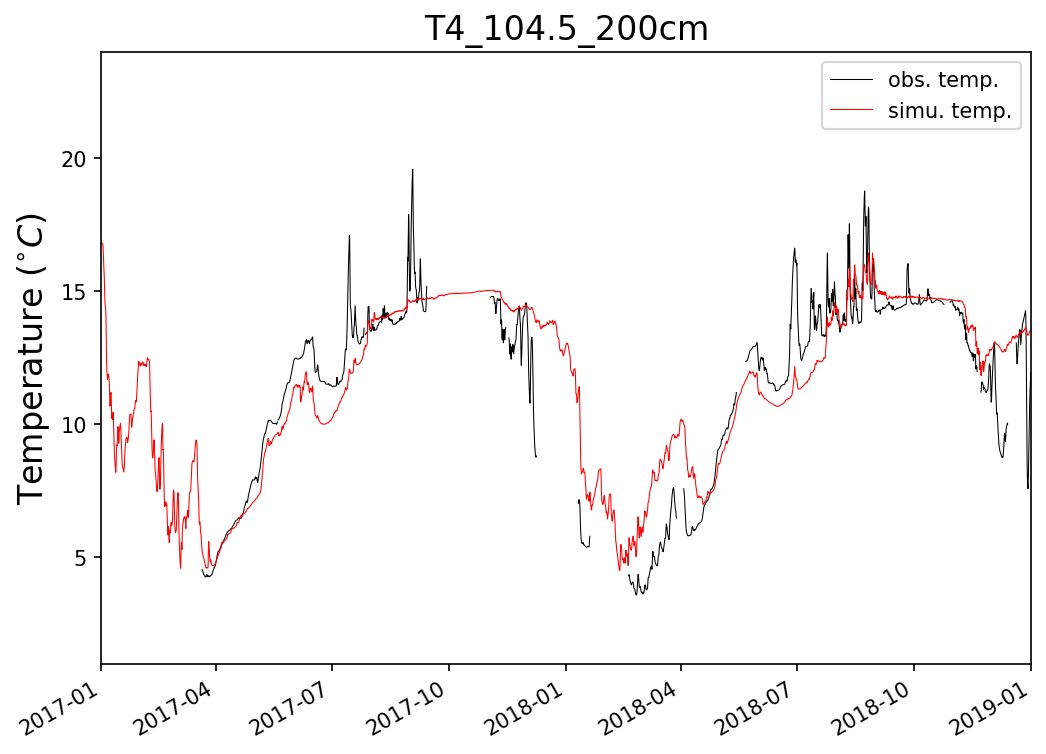

In [44]:
for iwell in tqdm(DA_wells[:1]):
    iwell = 'T4_104.5_200cm'
    iwell_id = well_screen[well_screen['WellName'] == iwell]['Well_ID'].values[0]

    iobs_df = DA_T.loc[:, iwell_id.replace('(', '.').replace(')', '.')].copy()
    # use 6-hr smoothing for observationd data (5 min freq)
    iobs_df[iobs_df < 0] = np.nan
    iobs_smooth = iobs_df.resample('6H', offset='3H').mean()
    isimu_df = well_data_df[iwell,'Temperature [C]', 'flux_ave_temp'].copy()

    fig, ax = plt.subplots(1,1, figsize=(8,6))

    # ax.plot(river_temp.index, river_temp['temp'],color = 'gray', alpha = 0.5, lw = 0.5)
    # river_temp.plot(y = 'temp', ax=ax, color = 'gray', alpha = 0.5, lw = 0.5)
    
    ax.plot(iobs_smooth.index,iobs_smooth.values, 'k-', lw=0.5)
    ax.plot(simu_time, isimu_df.values, 'r-', lw=0.5)
    # DA_cell_temp.plot(color='black', ax=ax)

    ax.set_ylabel('Temperature $(^{\circ}C)$', fontsize=16)
    ax.set_xlabel('')
    ax.set_xlim([pd.Timestamp('2017-01-01'), pd.Timestamp('01/01/2019')])
    ax.set_ylim([1, 24])
    # ax.xaxis.set_major_locator(mdates.YearLocator())
    # ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    # ax.xaxis.set_tick_params('labelbottom')
    fig.autofmt_xdate()

    # ax.tick_params(axis='both', which='major', labelsize=14)
    ax.legend(['obs. temp.','simu. temp.'], loc='best')
    # ax.legend(['river temp.','obs. temp.','simu. temp.'], loc='best')
    ax.set_title(iwell, fontsize=16)
    
    # fig.savefig(figure_dir + f"{case_name}simu_obs_temp/" + iwell + '_2019.jpg', dpi=300)
    # plt.close(fig)    

    

  0%|          | 0/1 [00:00<?, ?it/s]

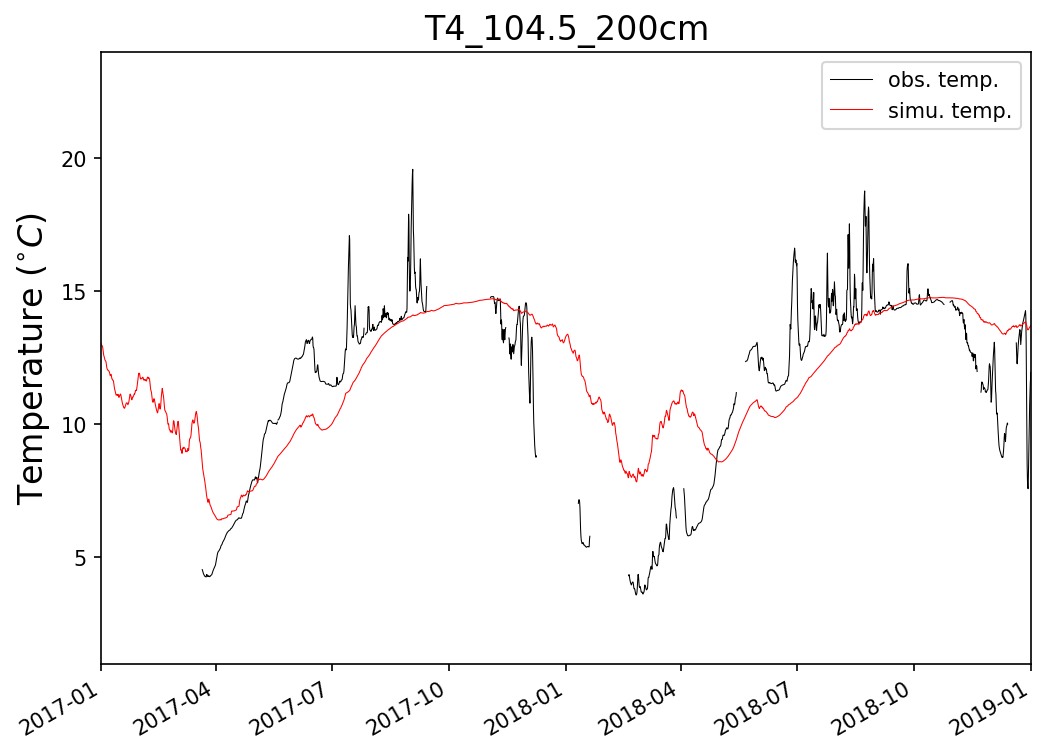

  0%|          | 0/1 [00:00<?, ?it/s]

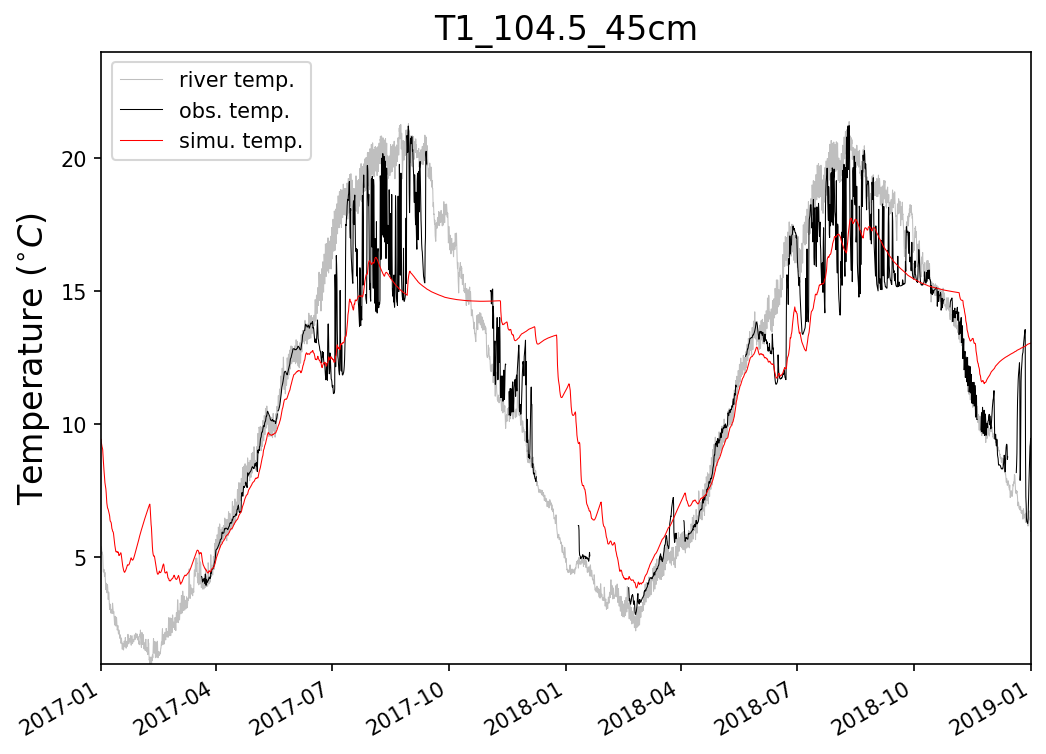

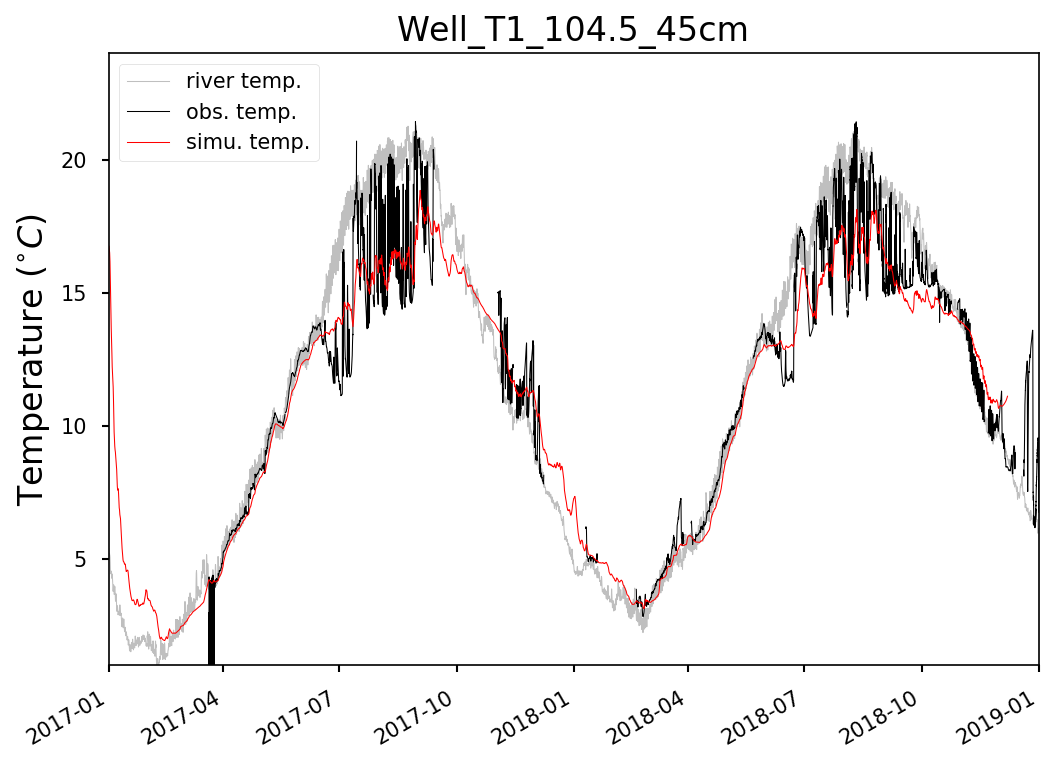

In [114]:
tube_list = ['Well_T5_105.5_54cm','Well_T5_105.5_100cm','Well_T5_105.5_200cm']

/global/homes/p/pshuai/.conda/envs/widget/lib/python3.6/site-packages/matplotlib/cbook/__init__.py:1402: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  ndim = x[:, None].ndim
/global/homes/p/pshuai/.conda/envs/widget/lib/python3.6/site-packages/matplotlib/axes/_base.py:276: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  x = x[:, np.newaxis]
/global/homes/p/pshuai/.conda/envs/widget/lib/python3.6/site-packages/matplotlib/axes/_base.py:278: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  y = y[:, np.newaxis]


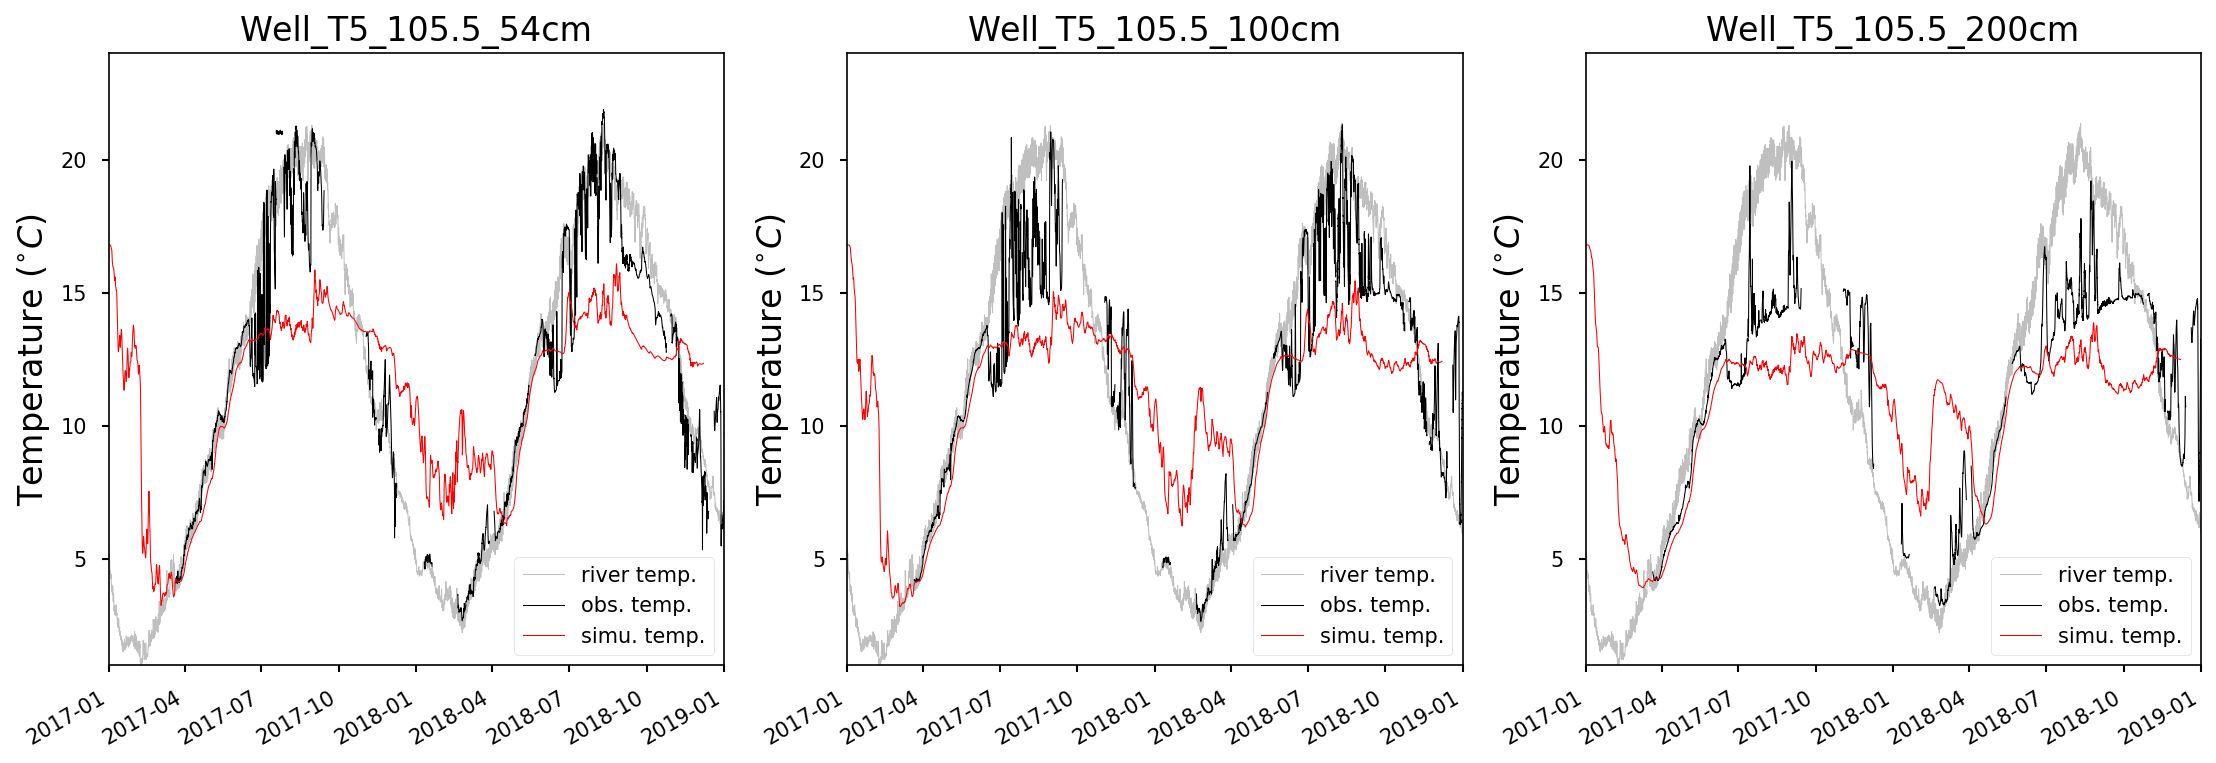

In [133]:

fig, axes = plt.subplots(1,3, figsize=(18,6))

for iwell, ax in zip(tube_list, axes.flatten()):
#     iwell = 'Well_T1_104.5_45cm'
    iwell_id = well_screen[well_screen['WellName'] == iwell.replace('Well_', '')]['Well_ID'].values[0]

    iobs_df = DA_T.loc[:, iwell_id.replace('(', '.').replace(')', '.')]
    isimu_df = well_data_df[iwell,'Temperature [C]', 'flux_ave_temp'].copy()

#     fig, ax = plt.subplots(1,1, figsize=(8,6))

    ax.plot(river_temp.index, river_temp['temp'],color = 'gray', alpha = 0.5, lw = 0.5)
    # river_temp.plot(y = 'temp', ax=ax, color = 'gray', alpha = 0.5, lw = 0.5)
    
    ax.plot(iobs_df.index,iobs_df.values, 'k-', lw=0.5)
    ax.plot(simu_time, isimu_df.values, 'r-', lw=0.5)
    # DA_cell_temp.plot(color='black', ax=ax)

    ax.set_ylabel('Temperature $(^{\circ}C)$', fontsize=16)
    ax.set_xlabel('')
    ax.set_xlim([pd.Timestamp('2017-01-01'), pd.Timestamp('01/01/2019')])
    ax.set_ylim([1, 24])
    # ax.xaxis.set_major_locator(mdates.YearLocator())
    # ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    # ax.xaxis.set_tick_params('labelbottom')
    fig.autofmt_xdate()

    # ax.tick_params(axis='both', which='major', labelsize=14)

    ax.legend(['river temp.','obs. temp.','simu. temp.'], loc='best')
    ax.set_title(iwell, fontsize=16)
    
#     fig.savefig(fname_simu_obs_temp + iwell + '.png', dpi=300)
#     plt.close(fig)

In [134]:
fig.savefig(out_dir + 'scatterplots/T5_105.5_temp_allinone.png', dpi=300)
plt.close(fig)

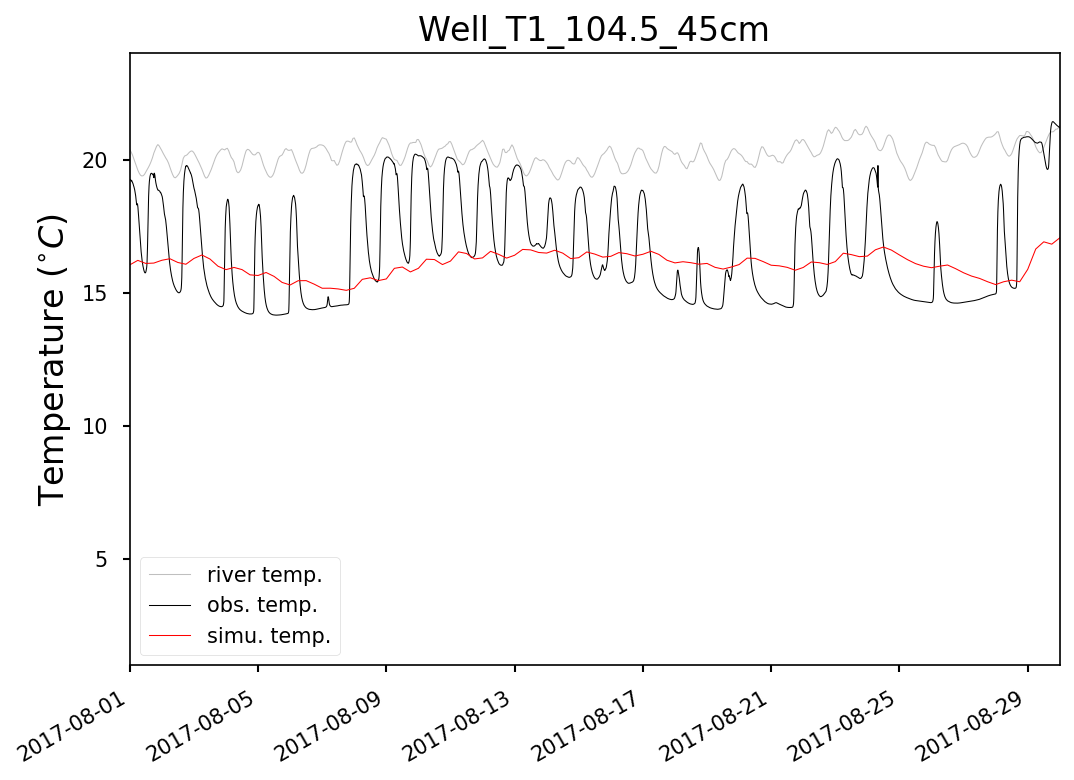

In [38]:
# zoom plot for k_al = 1 m/d

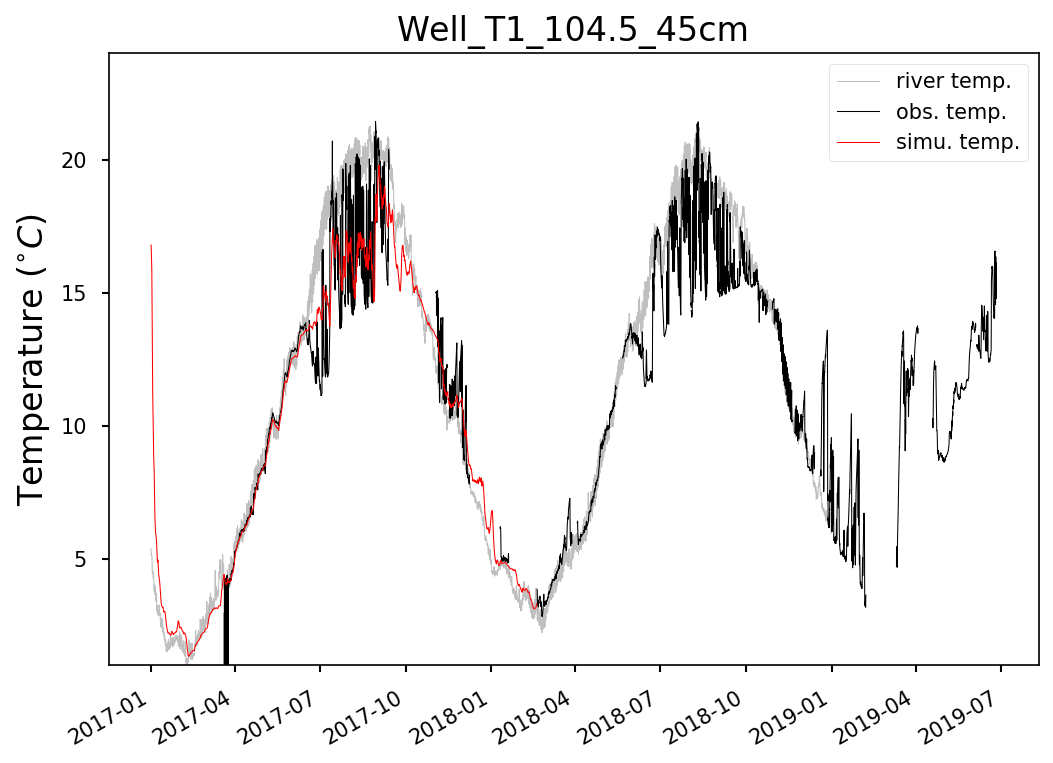

In [57]:
# k alluvium = 4.6 m/d

#### iButton

Because of the small interval in some iButton screen, the simulated temp maybe from the same nearest cell. Need to increase model vertical resolution.

In [98]:
metadata = pd.read_csv(iButton_dir + 'iButton_b1_to_d6_Summary.csv')

In [99]:
all_files = glob.glob(iButton_dir + '*.csv')

In [100]:
logger = 'b'
logger_files = [i for i in all_files if logger == i[-6] ]
logger_files = natsorted(logger_files)

In [101]:
iButton_wells = [i for i in piezometer_list if 'iButton' in i]

In [118]:
def plot_iButton_temp(iwell, smooth_window = None, flux_average = True, return_df = False, start_date = None, end_date = None):

#     iwell = iButton_wells[0]
    iwell_id = well_screen[well_screen['WellName'] == iwell]['Well_ID'].values[0]
    iwell_name = metadata[metadata['Name'] == iwell_id.replace('iButton', 'Zhou')]['Represent Name'].values[0]

    ilogger = [i for i in logger_files if iwell_name in i][0]

    # fig, ax = plt.subplots(1,1, figsize=(8,6))

    # isimu_df = well_data_df[iwell,'Temperature [C]', 'flux_ave_temp'].copy()
    
    # labels = ['river temperature']
    # for ifile in logger_files[2:]:
    iobs_df = pd.read_csv(ilogger, skiprows=1, names=['datetime', 'temp'])
    iobs_df = insertNA(iobs_df, 'datetime')
    # # use 6-hr smoothing for observationd data (5 min freq)
    iobs_df['datetime'] = pd.to_datetime(iobs_df['datetime'])
    iobs_df.set_index('datetime', inplace=True)
    if smooth_window is not None:
        iobs_df = iobs_df.resample(smooth_window).mean()
    
    # print(iobs_df.head())

    #     df.rename(columns={'# Datetime': 'datetime'}, inplace = True)

    isimu_df = well_data_df.loc[:, [(iwell,'Temperature [C]', 'flux_ave_temp')]].copy()
    
    # iwell_id = well_screen[well_screen['WellName'] == iwell]['Well_ID'].values[0]
    
    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])
    
    isimu_df['DateTime'] = pd.to_datetime(simu_time)
    isimu_df.set_index('DateTime', inplace=True)

    # if smooth_window is not None:
    #     # Apply rolling mean
    #     iobs_df = iobs_df.rolling(window=smooth_window).mean()

    # get metrics
    metric, _ = utils.get_metrics(iobs_df.index, iobs_df.iloc[:, 0].values, isimu_df.index, isimu_df.iloc[:, -1].values, 
                     metrics=['NSE', 'mKGE', 'RMSE'])
    print(metric)
    
    fig, ax = plt.subplots(1,1, figsize=(8,4))

    ax.plot(iobs_df.index,iobs_df.values, 'k-')
    if flux_average:
        ax.plot(simu_time, isimu_df.iloc[:, -1], 'r-')
    else:
        ax.plot(simu_time, isimu_df.iloc[:, 0], 'r-')

    if start_date is None:
        start_date = simu_time[0]
    if end_date is None:
        end_date = simu_time[-1]        
    
    ax.set_xlim([start_date, end_date])
    ax.set_ylim([0, 24])
    ax.legend(['obs. temp.', 'simu. temp.'],loc='best', frameon = False)
    # ax.set_title(iwell, fontsize = 16)
    ax.set_title(f"{iwell} (NSE:{metric['NSE']:.2f}, mKGE:{metric['mKGE']:.2f}, RMSE:{metric['RMSE']:.2f})", fontsize=16)
    ax.set_ylabel('Temperature $(^{\circ}C)$', fontsize=16)
    # ax.set_ylabel('Temp (${\degree}C$)')    
    
    if return_df:
        return fig, isimu_df, iobs_df
    else:
        return fig

{'NSE': -0.9483117656646671, 'mKGE': -0.09904397064612791, 'RMSE': 3.333637313146363}


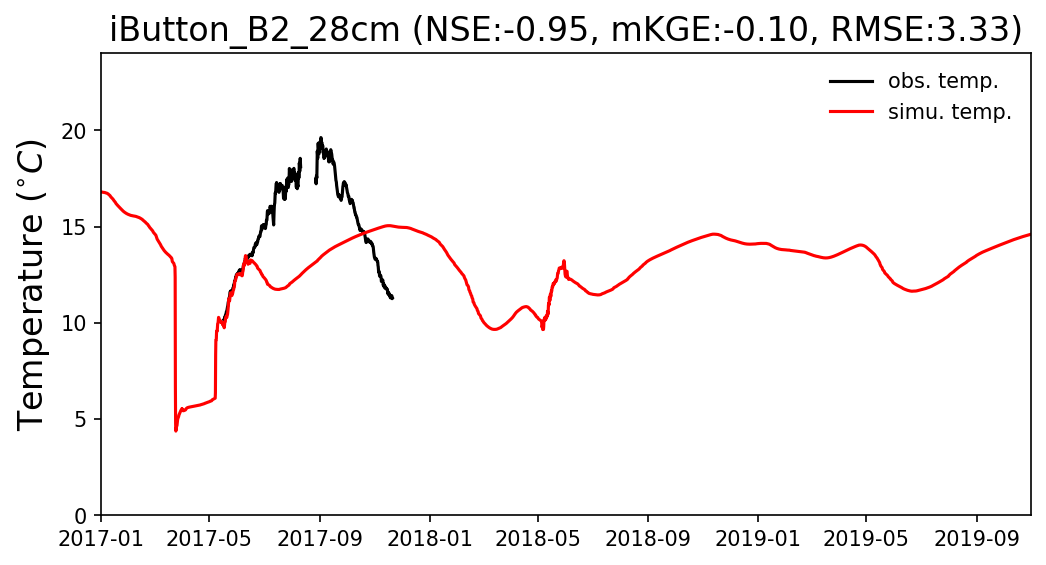

In [119]:
fig, isimu_df, iobs_df = plot_iButton_temp(iwell = 'iButton_B2_28cm', smooth_window='6H', flux_average=True, return_df=True)

{'NSE': -1.126888741739632, 'mKGE': -0.2933515734432779, 'RMSE': 3.9520086182205203}


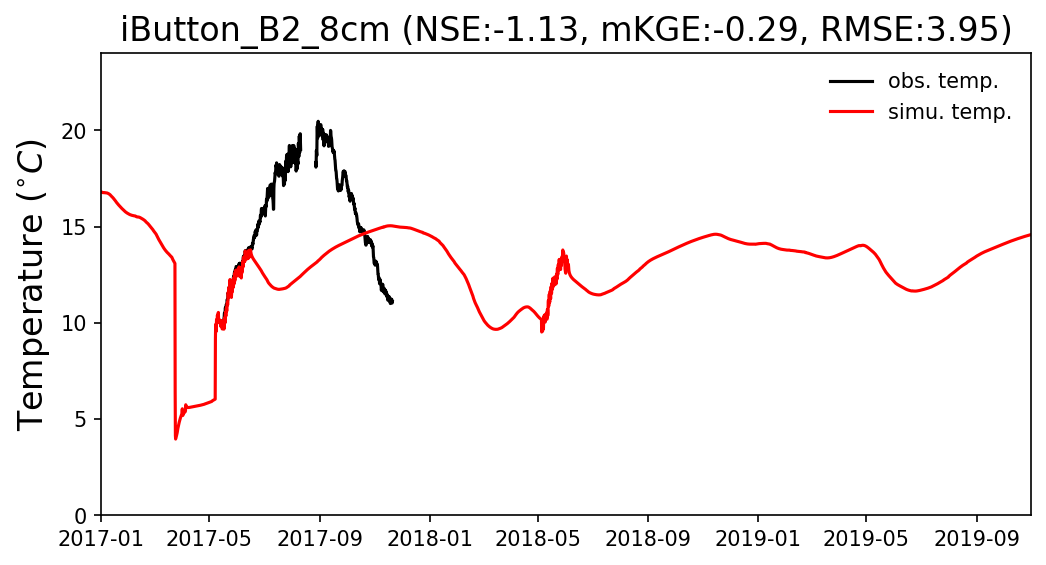

In [120]:
fig, isimu_df, iobs_df = plot_iButton_temp(iwell = 'iButton_B2_8cm', smooth_window='6H', flux_average=True, return_df=True)

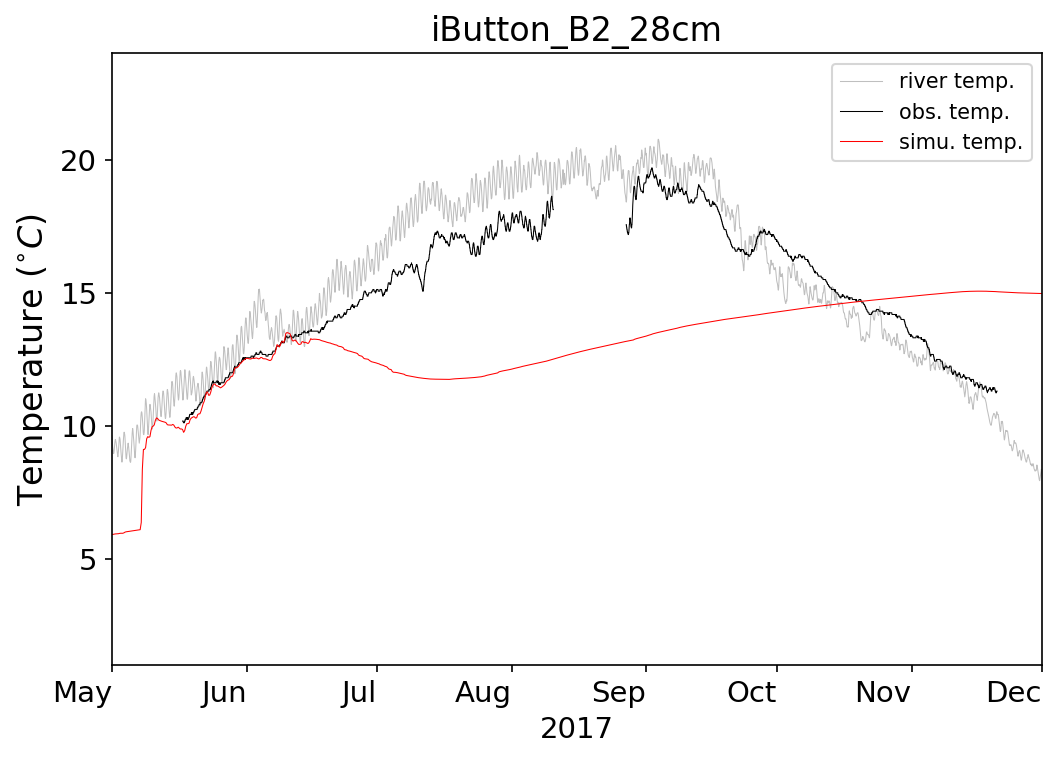

In [103]:
for iwell in iButton_wells[:1]:
#     iwell = iButton_wells[0]
    iwell_id = well_screen[well_screen['WellName'] == iwell]['Well_ID'].values[0]
    iwell_name = metadata[metadata['Name'] == iwell_id.replace('iButton', 'Zhou')]['Represent Name'].values[0]

    ilogger = [i for i in logger_files if iwell_name in i][0]

    fig, ax = plt.subplots(1,1, figsize=(8,6))

    isimu_df = well_data_df[iwell,'Temperature [C]', 'flux_ave_temp'].copy()
    # labels = ['river temperature']
    # for ifile in logger_files[2:]:
    df = pd.read_csv(ilogger, skiprows=1, names=['datetime', 'temp'])

    df = insertNA(df, 'datetime')
    #     df.rename(columns={'# Datetime': 'datetime'}, inplace = True)
    df['datetime'] = pd.to_datetime(df['datetime'])
    df.set_index('datetime', inplace=True)

    ax.plot(river_temp.index, river_temp['temp'], color = 'gray', alpha = 0.5, lw = 0.5)
    df.plot(y='temp', color = 'k', lw = 0.5, ax=ax)
    ax.plot(simu_time, isimu_df.values, 'r-', lw=0.5)    
    # iButton_cell_temp.plot(color='black', ax=ax)

    ax.set_xlim([pd.Timestamp('2017-05-01'), pd.Timestamp('2017-12-01')])
    ax.set_ylim([1, 24])

    monthyearFmt = mdates.DateFormatter('%b')
    ax.xaxis.set_major_formatter(monthyearFmt)
    _ = plt.xticks(rotation=0)

    # labels.append('simu. temp. (d=100 cm)')    
    ax.set_ylabel('Temperature $(^{\circ}C)$', fontsize=16)
    ax.set_xlabel('2017', fontsize=14)
    ax.tick_params(axis='both', which='major', labelsize=14)


    ax.set_title(iwell, fontsize=16)
    ax.legend(['river temp.', 'obs. temp.', 'simu. temp.'], loc='upper right')
    
    # fig.savefig(fname_simu_obs_temp + iwell + '.png', dpi=300)
    # plt.close(fig)
    

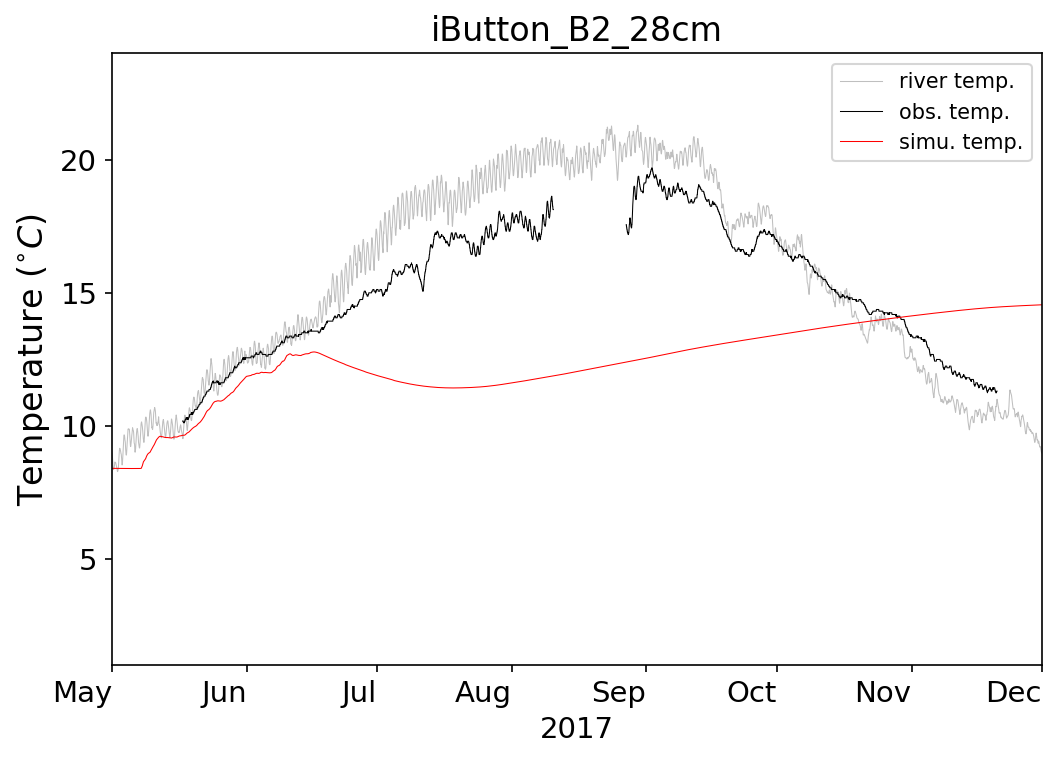

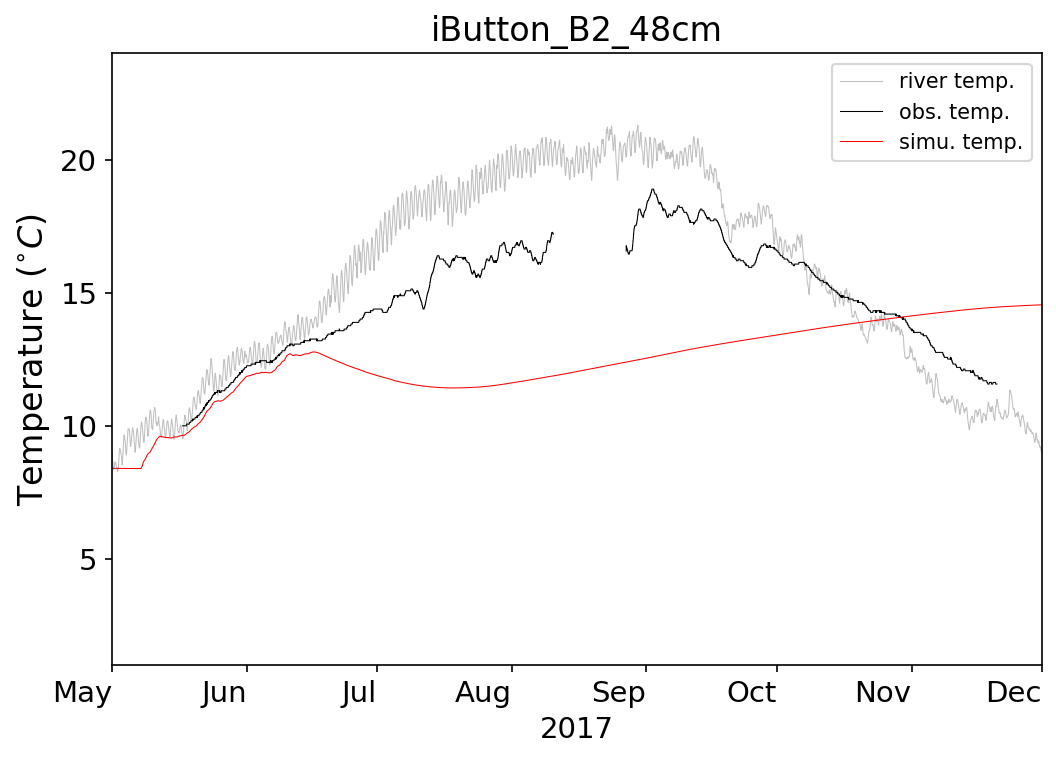

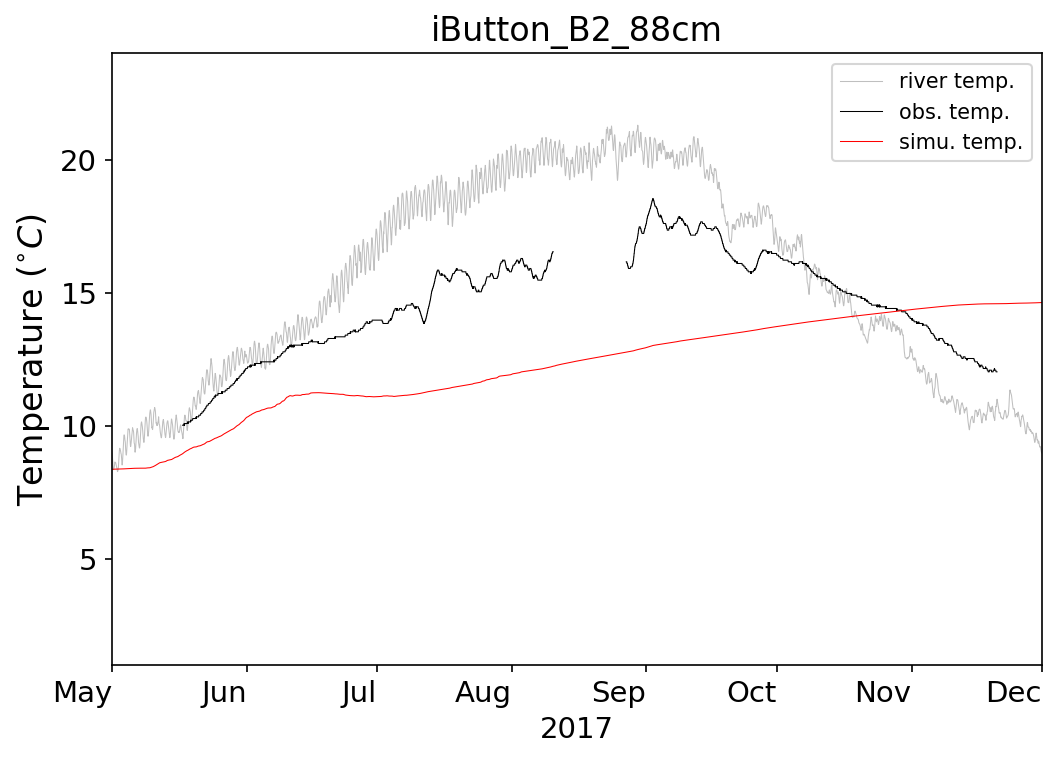

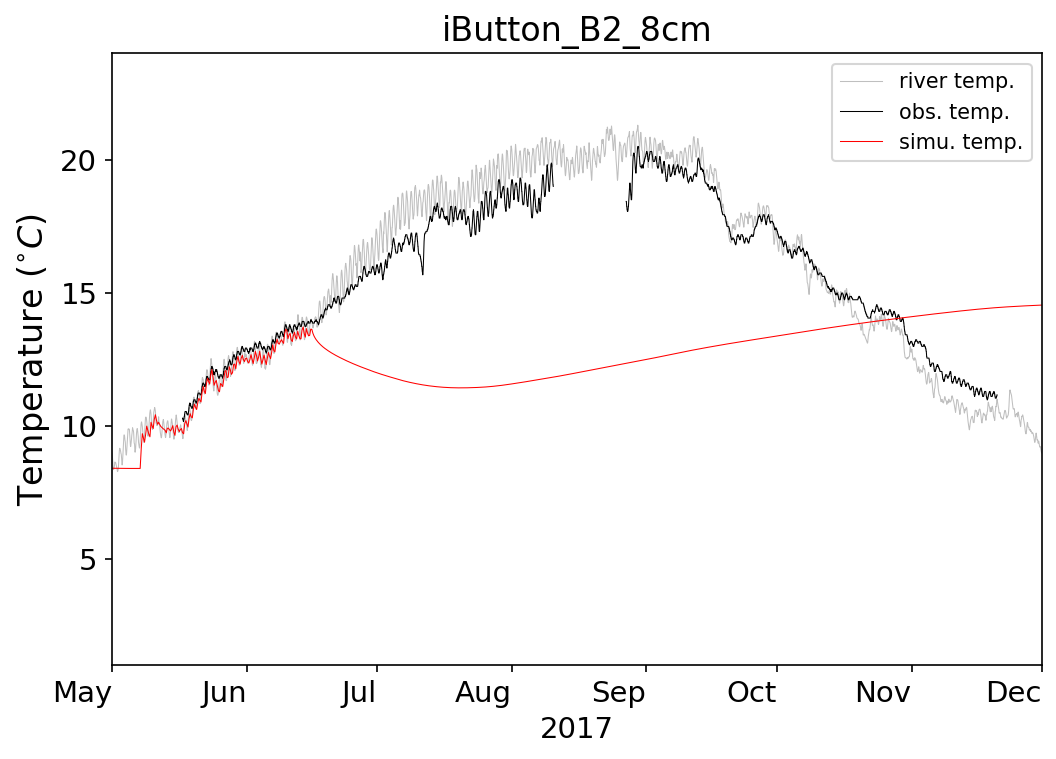

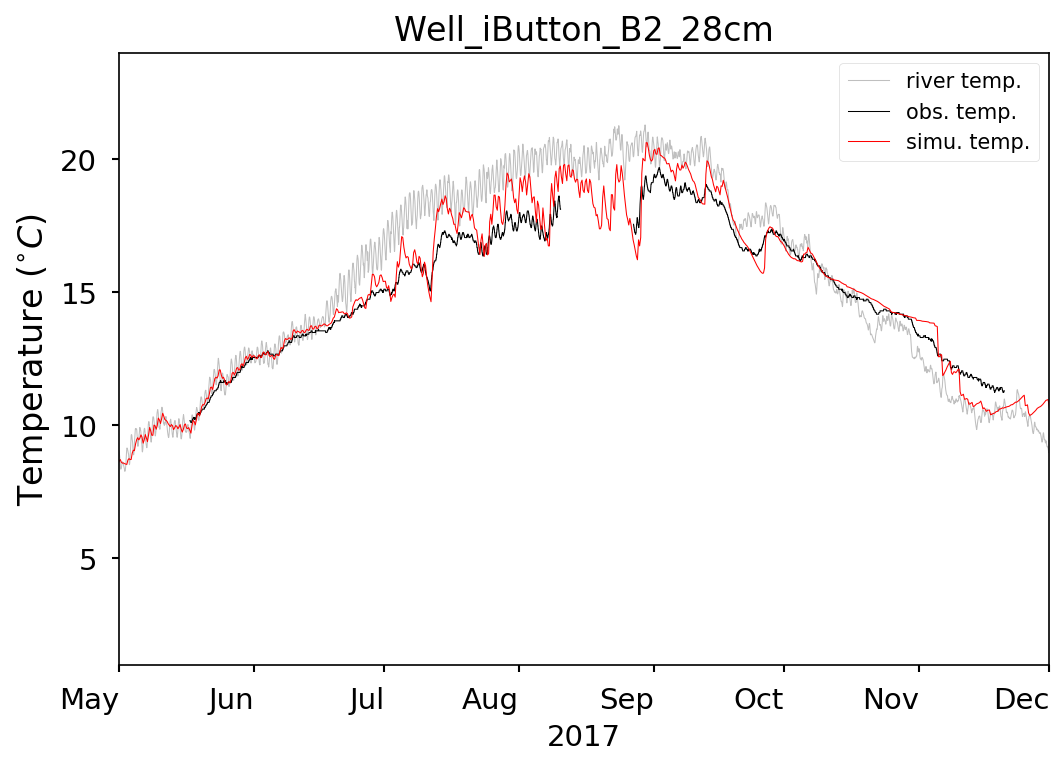

#### **RG3_T3**

In [143]:
RG3_T = pd.read_csv(fname_RG3_T, na_values = ['NAN'])
RG3_T.dropna(subset=['time'], inplace=True)
RG3_T = insertNA(RG3_T, 'time')
RG3_T.set_index('time', drop=True, inplace=True)

In [144]:
RG3_smooth = RG3_T.resample('6H').mean()

In [145]:
RG3_wells = [i for i in piezometer_list if 'RG3' in i]

{'NSE': 0.8639299090050209, 'mKGE': 0.9307026016391925, 'RMSE': 1.9613743613711132}
{'NSE': 0.8132856270888325, 'mKGE': 0.8664108373686443, 'RMSE': 2.2217842392530587}


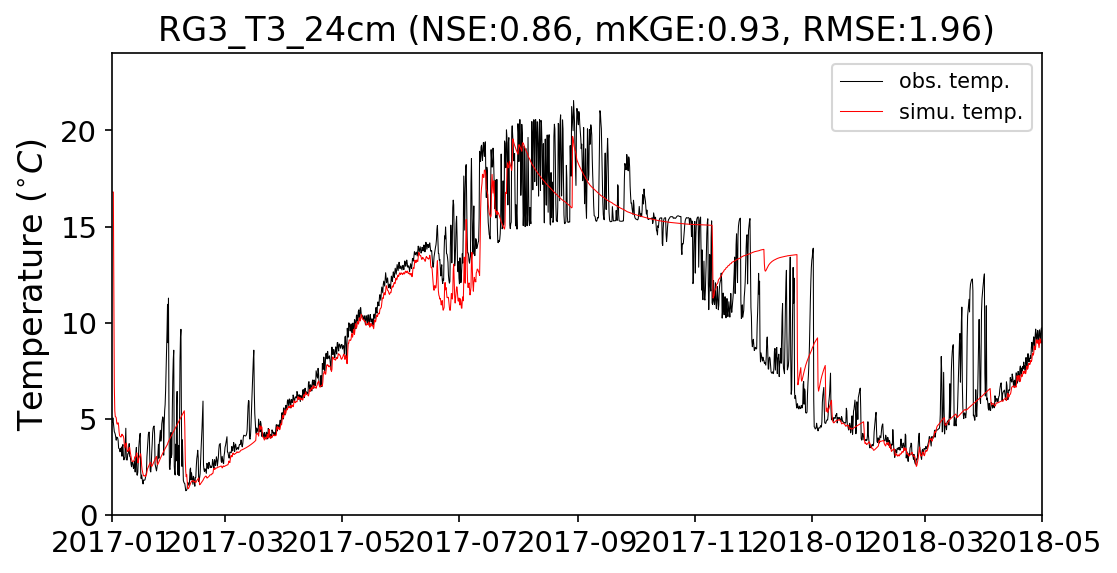

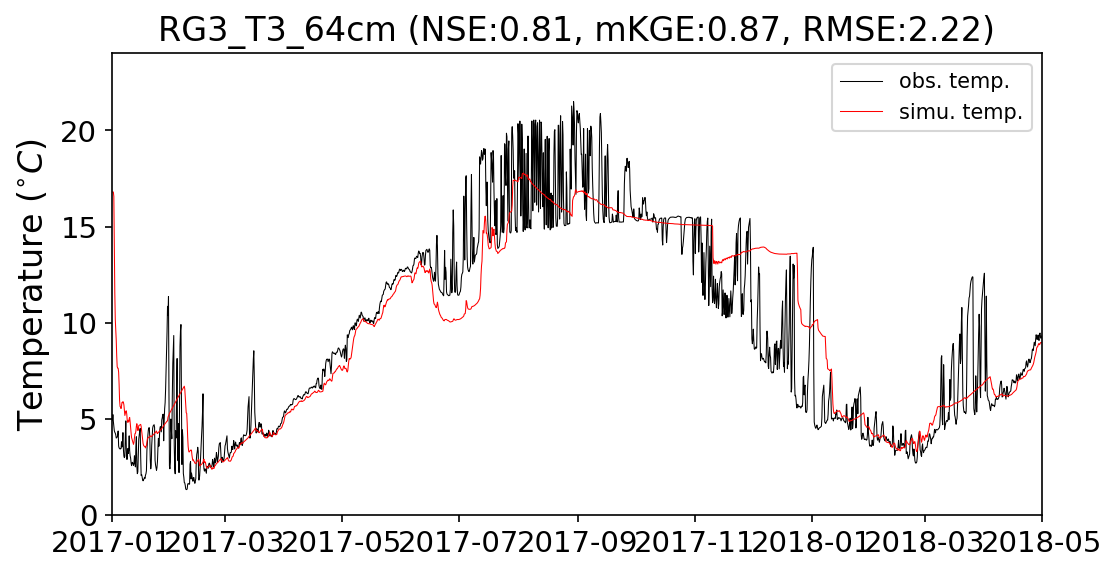

In [148]:
# iwell = RG3_wells[0]
for iwell, depth in zip(RG3_wells, ['mid', 'bot']):
    # isimu_df = well_data_df[iwell,'Temperature [C]', 'flux_ave_temp'].copy()
    isimu_df = well_data_df.loc[:, [(iwell,'Temperature [C]', 'flux_ave_temp')]].copy()
    simu_time = np.array([date_origin + timedelta(hours=i) for i in isimu_df.index])
    
    isimu_df['DateTime'] = pd.to_datetime(simu_time)
    isimu_df.set_index('DateTime', inplace=True)
    
    iobs_df = RG3_smooth[depth]
    # iobs_df['datetime'] = RG3_smooth.index

  
    # get metrics
    metric, _ = utils.get_metrics(iobs_df.index, iobs_df.values, isimu_df.index, isimu_df.iloc[:, -1].values, 
                     metrics=['NSE', 'mKGE', 'RMSE'])
    print(metric)

    
    fig, ax = plt.subplots(1,1, figsize=(8,4))

    # ax.plot(river_temp.index, river_temp['temp'], color = 'gray', alpha = 0.5, lw = 0.5)

    ax.plot(RG3_smooth.index, RG3_smooth[depth], color = 'k', lw= 0.5)
    # RG3_T.plot(x='time', y = ['bot'], color = 'k', ax=ax, lw= 0.5)
    ax.plot(simu_time, isimu_df.values, 'r-', lw=0.5) 

    ax.set_ylabel('Temperature $(^{\circ}C)$', fontsize=16)
    ax.set_xlabel('')
    ax.set_xlim([pd.Timestamp('2017-01-01'), pd.Timestamp('2018-05-01')])
    # ax.set_xlim(['1/1/2017', '1/1/2019'])
    ax.set_ylim([0, 24])
    ax.tick_params(axis='both', which='major', labelsize=14)

    ax.legend(['obs. temp.', 'simu. temp.'], loc='upper right')
    # ax.set_title(iwell, fontsize=16)    
    ax.set_title(f"{iwell} (NSE:{metric['NSE']:.2f}, mKGE:{metric['mKGE']:.2f}, RMSE:{metric['RMSE']:.2f})", fontsize=16)

# fig.savefig(fname_simu_obs_temp + iwell + '.png', dpi=300)
# plt.close(fig)

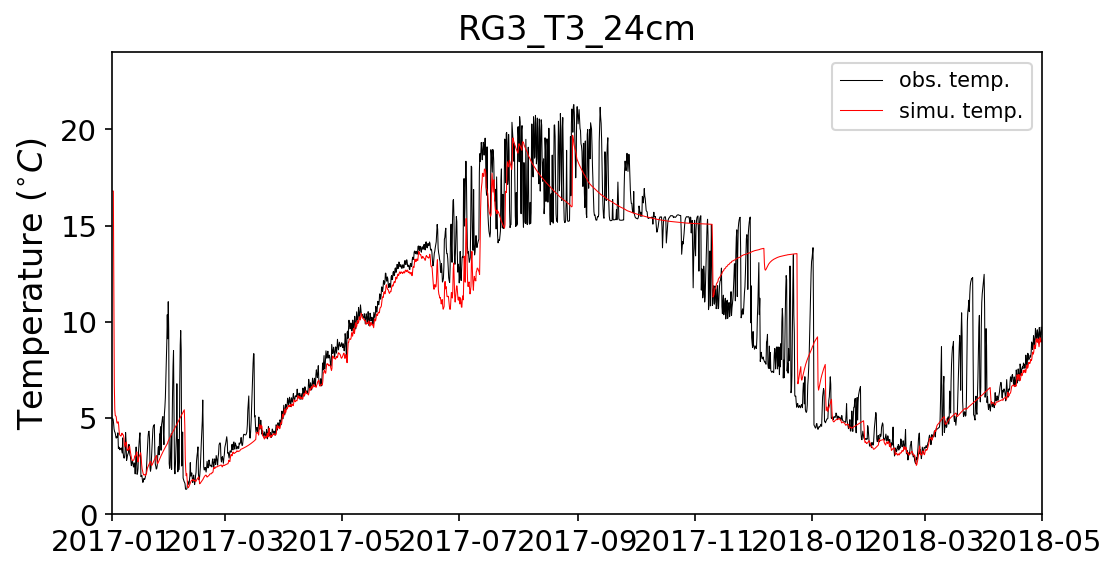

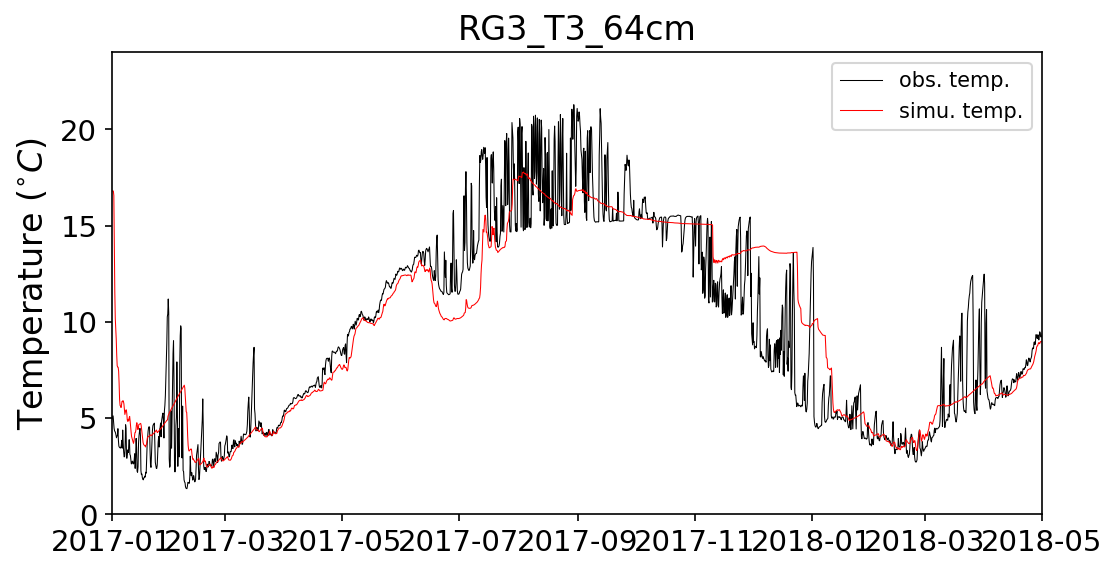

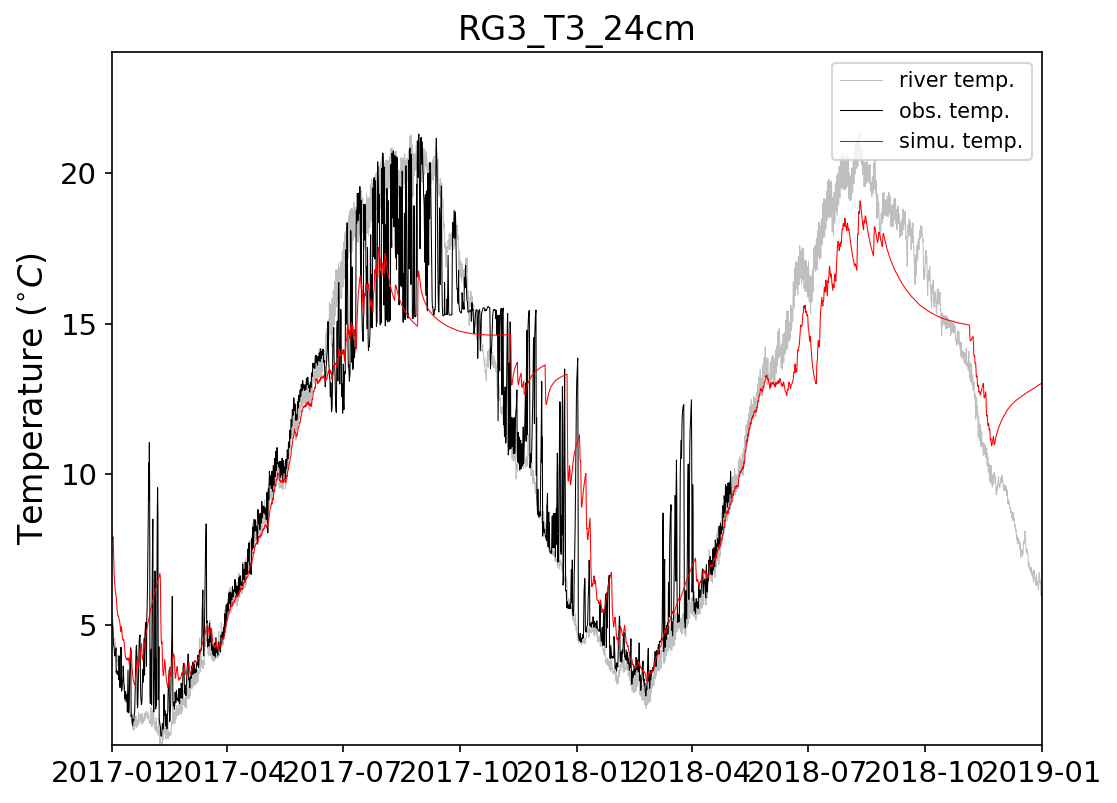

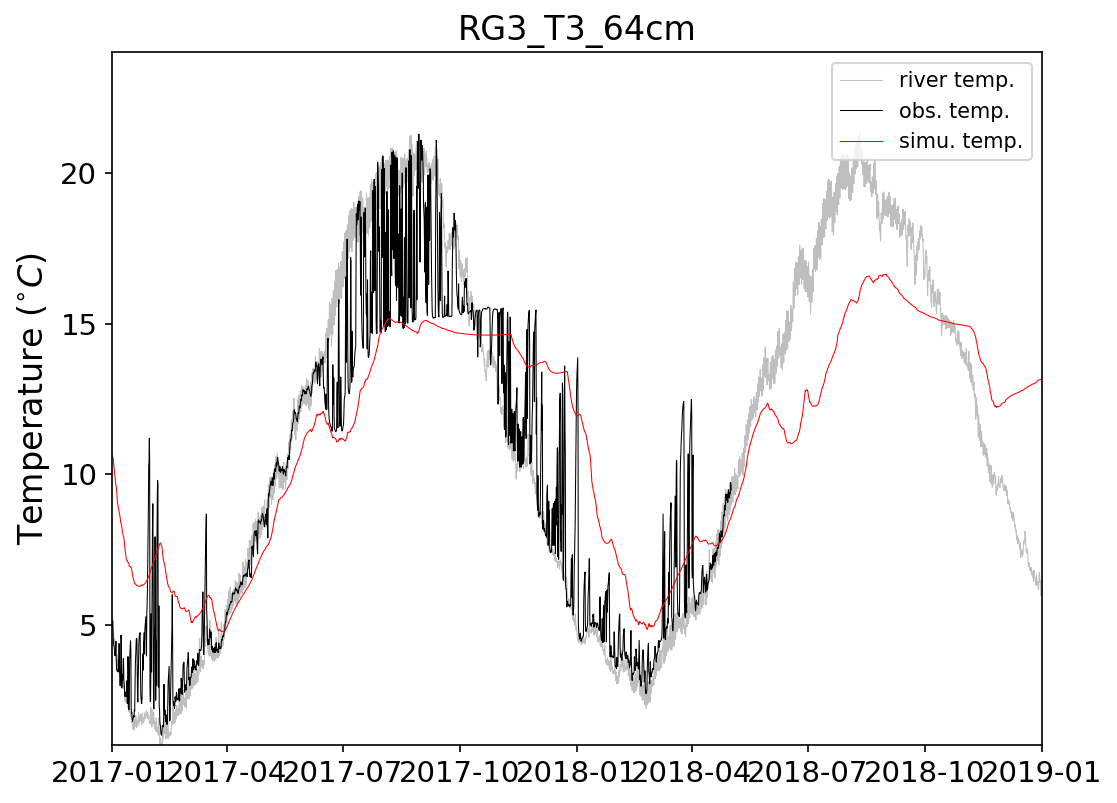

Text(0.5, 1.0, 'Well_RG3_T3_64cm')

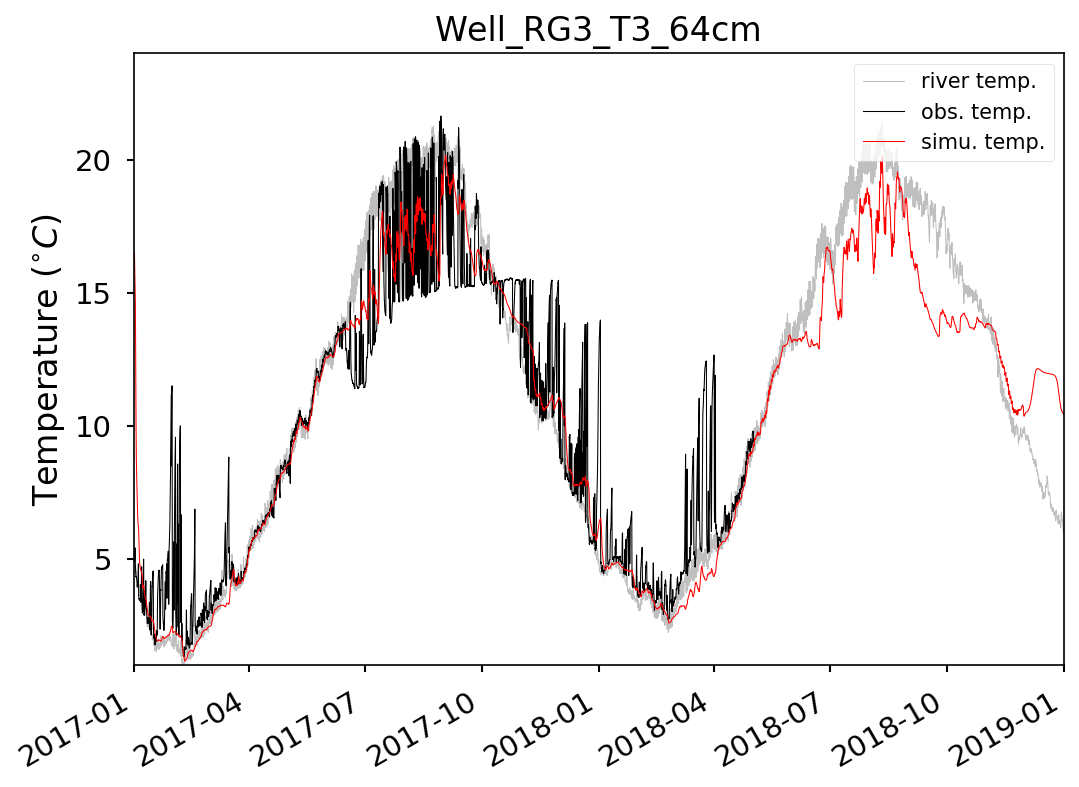